In [ ]:
# This cell needs to be run BEFORE any cell that uses pd
import pandas as pd
import numpy as np
df = pd.read_csv("/content/enhanced_compressor_data_v4_modified_power_noise (1).csv").sample(frac=0.5, random_state=42)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

correlation_columns = [
    'motor_rpm', 'pressure_bar', 'torque_nm', 'temperature_c', 'power_kw', 'vibration_rms',
    'airflow_demand_cfm', 'noise_db', 'pressure_change_rate', 'oilpump_power_w',
    'vibration_moving_avg', 'temperature_change_rate'
]

df = df[df['repair_status'] == 0].copy()

available_corr_columns = [col for col in correlation_columns if col in df.columns and pd.api.types.is_numeric_dtype(df[col])]

if len(available_corr_columns) < 2:
    print("خطأ: يجب توفر عمودين رقميين على الأقل لحساب الارتباط.")
else:
    print(f"جاري حساب مصفوفة الارتباط لأول 1000 سطر لـ {len(available_corr_columns)} متغير...")
    try:
        # اختيار أول 1000 سطر فقط
        subset_df = df.iloc[:100000]

        # حساب مصفوفة الارتباط
        correlation_matrix = subset_df[available_corr_columns].corr()

        # طباعة مصفوفة الارتباط كأرقام
        print("\nمصفوفة الارتباط (Correlation Matrix) كأرقام:")
        print(correlation_matrix.to_string(float_format="%.2f"))

        plt.figure(figsize=(10, 7))

        sns.heatmap(correlation_matrix,
                    annot=True,
                    cmap='coolwarm',
                    fmt=".2f",
                    linewidths=.5,
                    linecolor='lightgray',
                    annot_kws={"size": 7})

        plt.title('Correlation Matrix', fontsize=16)
        plt.xticks(rotation=45, ha='right', fontsize=8)
        plt.yticks(rotation=0, fontsize=8)
        plt.tight_layout()
        plt.show()
    except Exception as e:
        # This print statement should be inside the except block
        print(f"حدث خطأ أثناء حساب أو رسم مصفوفة الارتباط: {e}")

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("\nالخطوة الثالثة أ: تحليل توزيع المتغيرات باستخدام مخططات الكثافة (Density Plots)")
print("="*75)
print("سيتم رسم مخططات الكثافة للمتغيرات الواعدة، مع فصل المنحنيات حسب نوع العطل.")
print("سيتم عرض القيم فقط عندما تكون repair_status = 0 وfault_type بين 0 و5 (الحالة الطبيعية والأعطال الموجبة).")

# افتراض أن df متاح بالفعل
# التحقق من وجود العمود repair_status
if 'repair_status' not in df.columns:
    print("خطأ: العمود 'repair_status' غير موجود في البيانات.")
    exit()

# تصفية البيانات لعرض القيم فقط عندما تكون repair_status = 0 وfault_type بين 0 و5
df_filtered = df[(df['repair_status'] == 0) & (df['fault_type'].between(-1, 5))].copy()

# تحديد قاموس لتسمية الأعطال
fault_type_labels = {
    0: "Normal",
    -1:"Leak",
    2: "Blockage",
    3: "Motor Wear",
    4: "Mechanical Failure",
    5: "Overheating"
}

# إنشاء عمود جديد بأسماء الأعطال بدلاً من الأرقام
df_filtered['fault_type_name'] = df_filtered['fault_type'].map(fault_type_labels)

# تحديد الأعمدة لرسم مخططات الكثافة
density_columns = [
    'temperature_c',
    'vibration_rms',
    'power_kw',
    'pressure_bar',
    'motor_rpm','airflow_demand_cfm'

]

# التأكد من أن الأعمدة موجودة
available_density_columns = [col for col in density_columns if col in df_filtered.columns]

if not available_density_columns:
    print("خطأ: لم يتم العثور على أي من الأعمدة المحددة لرسم مخططات الكثافة.")
else:
    num_density_plots = len(available_density_columns)
    num_density_cols = 2
    num_density_rows = (num_density_plots + num_density_cols - 1) // num_density_cols

    fig_density, axes_density = plt.subplots(nrows=num_density_rows, ncols=num_density_cols, figsize=(14, num_density_rows * 4.5))
    axes_density = axes_density.flatten()

    print(f"جاري إنشاء {num_density_plots} مخطط كثافة (Density Plot)...")

    # تحديد لوحة ألوان مميزة
    try:
        unique_fault_types = sorted(df_filtered['fault_type_name'].unique())
        palette = sns.color_palette("tab10", n_colors=len(unique_fault_types))
        palette_dict = dict(zip(unique_fault_types, palette))
    except:
        palette_dict = None

    for i, col_name in enumerate(available_density_columns):
        ax = axes_density[i]
        try:
            # إنشاء مخطط الكثافة مع فصل الألوان حسب fault_type_name
            sns.kdeplot(data=df_filtered,
                        x=col_name,
                        hue='fault_type_name',
                        ax=ax,
                        fill=True,
                        common_norm=False,
                        palette=palette_dict,
                        alpha=0.4,
                        linewidth=1.5,
                        bw_adjust=0.75)

            ax.set_title(f'Density Plot for: {col_name} (repair_status = 0)', fontsize=10)
            ax.set_xlabel(col_name, fontsize=8)
            ax.set_ylabel('Density', fontsize=8)
            ax.tick_params(axis='both', which='major', labelsize=8)

            # تعديل حجم الـ legend
            handles, labels = ax.get_legend_handles_labels()
            if handles:
                ax.legend(handles, labels, title='Fault Type', fontsize='x-small', title_fontsize='small')

        except Exception as e:
            print(f"حدث خطأ أثناء رسم العمود {col_name}: {e}")
            ax.set_title(f'Error plotting density: {col_name}', fontsize=10)

    # إخفاء المحاور الفارغة
    for j in range(i + 1, len(axes_density)):
        fig_density.delaxes(axes_density[j])

    plt.tight_layout(rect=[0, 0.03, 1, 0.96])
    plt.suptitle('Density Plots of Key Variables by Fault Type (repair_status = 0, Faults 0-5)', fontsize=14, y=0.99)
    plt.show()

    print("\n--- انتهت خطوة مخططات الكثافة ---")
    print("تحليل مخططات الكثافة:")
    print("* لاحظ كيف يتغير شكل وموقع (القمة/التركيز) لكل منحنى حسب نوع العطل.")
    print("* هل هناك تداخل كبير بين منحنى الحالة الطبيعية (Normal) ومنحنيات الأعطال؟ أم هناك انفصال واضح؟")
    print("* هل شكل التوزيع (مثلاً، هل له قمة واحدة أم أكثر؟ هل هو ملتوي؟) يختلف بين الحالات؟")

In [ ]:
import pandas as pd
import numpy as np

# Load the input data
df = pd.read_csv("/content/noisy_compressor_data_v5 (1).csv")

# Verify 'id' column exists and is unique/sequential
if 'id' not in df.columns:
    raise ValueError("Column 'id' not found in the dataset. Please ensure it is added.")
if not df['id'].is_unique:
    raise ValueError("Column 'id' contains duplicate values. Ensure each 'id' is unique.")
if not (df['id'].diff().dropna() >= 1).all():
    raise ValueError("Column 'id' is not sequential. Ensure 'id' increments correctly.")

# Drop 'time_min' if it exists
df = df.drop(columns=['time_min'], errors='ignore')

# Sort by 'id' for chronological order
df = df.sort_values(by='id')

# Initialize 'time_to_failure' column
df['time_to_failure'] = np.nan

# Identify fault start times (fault_type from 1 to 5)
fault_starts = df[df['fault_type'].isin([1, 2, 3, 4, 5])].groupby('id').first().reset_index()
fault_times = fault_starts['id'].values

# Calculate time_to_failure for each row
for i, row in df.iterrows():
    current_time = row['id']
    future_faults = fault_times[fault_times > current_time]
    if len(future_faults) > 0:
        next_fault_time = future_faults[0]
        df.loc[i, 'time_to_failure'] = next_fault_time - current_time  # In seconds
    else:
        df.loc[i, 'time_to_failure'] = 0

# Save the updated dataset
df.to_csv("enhanced_compressor_data_v4_with_ttf.csv", index=False)
print("Created 'enhanced_compressor_data_v4_with_ttf.csv' with 'time_to_failure' column.")

Created 'enhanced_compressor_data_v4_with_ttf.csv' with 'time_to_failure' column.


Applying feature engineering to training data...


<ipython-input-7-66ef76670621>:45: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data_df[f'{col}_min_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).min()
<ipython-input-7-66ef76670621>:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data_df[f'{col}_max_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).max()
<ipython-input-7-66ef76670621>:48: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poo

Applying feature engineering to test data...


<ipython-input-7-66ef76670621>:45: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data_df[f'{col}_min_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).min()
<ipython-input-7-66ef76670621>:46: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data_df[f'{col}_max_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).max()
<ipython-input-7-66ef76670621>:48: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poo


Data points in training set (0 < TTF <= 7200.0 seconds): 80000
Data points in test set (0 < TTF <= 7200.0 seconds): 19368

Calculated Class Weights: {np.int64(0): np.float64(1.1035091591260207), np.int64(1): np.float64(0.8333333333333334), np.int64(2): np.float64(0.6373689410115045), np.int64(3): np.float64(3.0783438510081576)}

Distribution of RUL Classes in Training Set:
rul_class
0    18124
1    24000
2    31379
3     6497
Name: count, dtype: int64

Running Randomized Search for 80 iterations with scoring 'f1_weighted'...
Fitting 5 folds for each of 1 candidates, totalling 5 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 1 is smaller than n_iter=80. Running 1 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(



Best parameters found: {'subsample': 0.7, 'reg_lambda': 0.001, 'reg_alpha': 0.01, 'n_estimators': 1000, 'min_child_weight': 1, 'max_depth': 25, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.7}

Training finished using the best model.

--- Multi-class Classification Performance (Test Set, RUL 0-7200 seconds) ---
Overall Accuracy: 0.960

Classification Report:
              precision    recall  f1-score   support

    0-10 min       0.97      0.97      0.97      4893
   10-30 min       0.96      0.94      0.95      6000
   30-60 min       0.95      0.98      0.97      7304
  60-120 min       0.94      0.87      0.91      1171

    accuracy                           0.96     19368
   macro avg       0.96      0.94      0.95     19368
weighted avg       0.96      0.96      0.96     19368



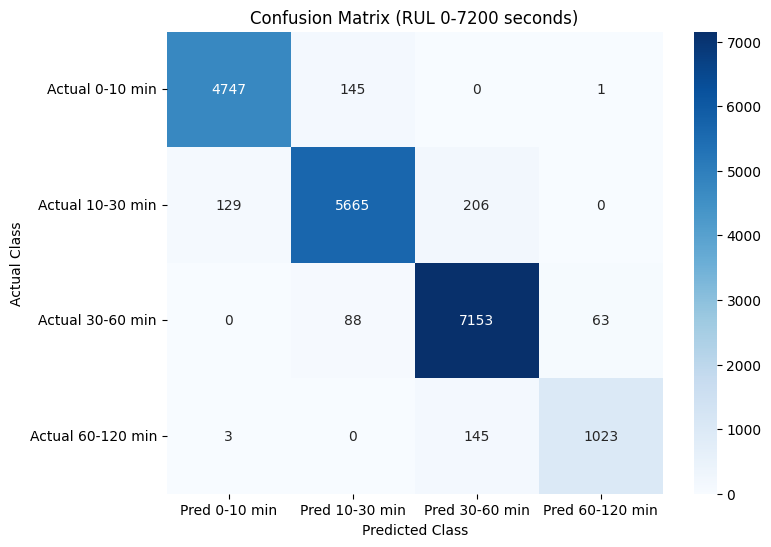


--- Sample of Multi-class Predictions (RUL 0-7200 seconds) ---
     time_dhms  actual_rul_class  predicted_rul_class  actual_ttf_seconds  \
0   0:22:13:21                 2                    2              2704.0   
1   0:22:13:22                 2                    2              2703.0   
2   0:22:13:23                 2                    2              2702.0   
3   0:22:13:24                 2                    2              2701.0   
4   0:22:13:25                 2                    2              2700.0   
5   0:22:13:26                 2                    2              2699.0   
6   0:22:13:27                 2                    2              2698.0   
7   0:22:13:28                 2                    2              2697.0   
8   0:22:13:29                 2                    2              2696.0   
9   0:22:13:30                 2                    2              2695.0   
10  0:22:13:31                 2                    2              2694.0   
11  0:22:13:

In [ ]:
# @title 2t
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import class_weight
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Function to convert seconds to days:hours:minutes:seconds format
def seconds_to_dhms(seconds):
    if pd.isna(seconds) or seconds < 0:
        return "N/A"
    days = int(seconds // (24 * 3600))
    seconds %= 24 * 3600
    hours = int(seconds // 3600)
    seconds %= 3600
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{days}:{hours:02d}:{minutes:02d}:{seconds:02d}"

# Function to create derived features with rolling windows in seconds
# ... (other imports and code remain unchanged)

# Function to create derived features with rolling windows in seconds
def create_features(data_df):
    data_df = data_df.sort_values(by='id').reset_index(drop=True)
    data_df = data_df.copy()
    epsilon = 1e-8  # Avoid division by zero

    # Recommended window sizes in seconds
    window_sizes_points = [600, 1800, 3600, 5400]
    core_features = ['pressure_bar', 'temperature_c', 'vibration_rms', 'power_kw']

    for window_size in window_sizes_points:
        if window_size > len(data_df):
            print(f"Warning: Window size {window_size} is larger than dataset length ({len(data_df)}). Skipping.")
            continue
        for col in core_features:
            data_df[f'{col}_mean_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).mean()
            data_df[f'{col}_std_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).std()
            data_df[f'{col}_min_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).min()
            data_df[f'{col}_max_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).max()
            if window_size > 2:
                data_df[f'{col}_skew_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).skew()
                data_df[f'{col}_kurt_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).kurt()
        for col in core_features:
            data_df[f'{col}_diff_{window_size}sec'] = data_df[col].diff(periods=window_size)
            data_df[f'time_diff_{window_size}sec'] = data_df['id'].diff(periods=window_size)
            data_df[f'{col}_change_rate_{window_size}sec'] = data_df[f'{col}_diff_{window_size}sec'] / (data_df[f'time_diff_{window_size}sec'] + epsilon)
            data_df = data_df.drop(columns=[f'{col}_diff_{window_size}sec', f'time_diff_{window_size}sec'], errors='ignore')

    data_df = data_df.fillna(method='bfill').fillna(0)
    return data_df

# Function to map time_to_failure to RUL classes
def map_ttf_to_class(ttf):
    if pd.isna(ttf) or ttf <= 0 or ttf > 7200:
        return -1
    elif ttf <= 600:
        return 0
    elif ttf <= 1800:
        return 1
    elif ttf <= 3400:
        return 2
    elif ttf <= 7200:
        return 3
    else:
        return -1

# Load the dataset
try:
    df = pd.read_csv("enhanced_compressor_data_v4_with_ttf.csv")
except FileNotFoundError:
    print("Error: File 'enhanced_compressor_data_v4_with_ttf.csv' not found.")
    exit()

# Ensure 'time_to_failure' exists
if 'time_to_failure' not in df.columns:
    raise ValueError("Column 'time_to_failure' not found.")
df.dropna(subset=['time_to_failure'], inplace=True)

# Sort by 'id' and reset index
df = df.sort_values(by='id').reset_index(drop=True)

# Step 1: Split data temporally (80/20)
train_size_ratio = 0.8
train_size_index = int(train_size_ratio * len(df))
train_df = df.iloc[:train_size_index].copy()
test_df = df.iloc[train_size_index:].copy()

# Step 2: Apply feature engineering
print("Applying feature engineering to training data...")
train_df = create_features(train_df)
print("Applying feature engineering to test data...")
test_df = create_features(test_df)

# Step 3: Assign RUL classes
max_classification_ttf = 7200.0
train_df['rul_class'] = train_df['time_to_failure'].apply(map_ttf_to_class)
test_df['rul_class'] = test_df['time_to_failure'].apply(map_ttf_to_class)

# Filter data to keep valid RUL classes
train_df_filtered = train_df[(train_df['rul_class'] != -1) & (train_df['time_to_failure'] > 0)].copy()
test_df_filtered = test_df[(test_df['rul_class'] != -1) & (test_df['time_to_failure'] > 0)].copy()

print(f"\nData points in training set (0 < TTF <= {max_classification_ttf} seconds): {len(train_df_filtered)}")
print(f"Data points in test set (0 < TTF <= {max_classification_ttf} seconds): {len(test_df_filtered)}")

if len(train_df_filtered) == 0 or len(test_df_filtered) == 0:
    raise ValueError("Not enough data points in the specified TTF range for classification.")

# Step 4: Define features and target
exclude_cols = ['id', 'fault_type', 'time_to_failure', 'is_failure', 'rul_class', 'is_failure_soon']
features = [col for col in train_df_filtered.columns if col not in exclude_cols]
features = [f for f in features if not any(sub in f for sub in ['_short', '_long', '_diff'])]

X_train = train_df_filtered[features]
y_train = train_df_filtered['rul_class']
X_test = test_df_filtered[features]
y_test = test_df_filtered['rul_class']

# Step 5: Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 6: Compute class weights for imbalance
classes = np.unique(y_train)
if len(classes) != 4:
    print(f"Warning: Found {len(classes)} unique classes in training data, expected 4.")
    print(f"Classes found: {classes}")
weights = class_weight.compute_class_weight('balanced', classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))
print("\nCalculated Class Weights:", class_weights)
print("\nDistribution of RUL Classes in Training Set:")
print(y_train.value_counts().sort_index())

# Step 7: Train XGBoost model with RandomizedSearchCV
base_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=len(classes),
    random_state=42,
    eval_metric='mlogloss'
)

param_dist = {
    'n_estimators': [1000],
    'max_depth': [25],
    'learning_rate': [0.1],
    'subsample': [0.7],
    'colsample_bytree': [0.7],
    'min_child_weight': [1],
    'gamma': [0.1],
    'reg_alpha': [0.01],
    'reg_lambda': [0.001]
}

scoring_metric = 'f1_weighted'
n_iter_search = 80
cv_folds = 5

print(f"\nRunning Randomized Search for {n_iter_search} iterations with scoring '{scoring_metric}'...")
random_search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_dist,
    n_iter=n_iter_search,
    scoring=scoring_metric,
    cv=cv_folds,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_scaled, y_train, sample_weight=np.array([class_weights[i] for i in y_train]))
print("\nBest parameters found:", random_search.best_params_)
best_model = random_search.best_estimator_
print("\nTraining finished using the best model.")

# Step 8: Predict and evaluate
y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)

class_names = ['0-10 min', '10-30 min', '30-60 min', '60-120 min']
print(f"\n--- Multi-class Classification Performance (Test Set, RUL 0-{int(max_classification_ttf)} seconds) ---")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'Pred {name}' for name in class_names],
            yticklabels=[f'Actual {name}' for name in class_names])
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title(f'Confusion Matrix (RUL 0-{int(max_classification_ttf)} seconds)')
plt.show()

# Step 9: Analyze predictions
test_df_results = test_df_filtered.copy().reset_index(drop=True)
test_df_results['predicted_rul_class'] = y_pred
test_df_results['actual_rul_class'] = y_test.values
test_df_results['predicted_proba'] = [y_pred_proba[i, predicted_class] for i, predicted_class in enumerate(y_pred)]
test_df_results['actual_ttf_seconds'] = test_df_filtered['time_to_failure'].values
test_df_results['time_dhms'] = test_df_results['id'].apply(seconds_to_dhms)

print(f"\n--- Sample of Multi-class Predictions (RUL 0-{int(max_classification_ttf)} seconds) ---")
print(test_df_results[['time_dhms', 'actual_rul_class', 'predicted_rul_class', 'actual_ttf_seconds', 'predicted_proba']].head(20))

# Analyze warnings (RUL <= 60 seconds)
warning_classes = [0, 1, 2]
warning_classes_names = ['0-10 sec', '10-30 sec', '30-60 sec']
warning_schedule_analysis = test_df_results[test_df_results['predicted_rul_class'].isin(warning_classes)].copy()

if not warning_schedule_analysis.empty:
    print(f"\n--- Analysis for Warnings Triggered (Predicted RUL {warning_classes_names}: 0-60 seconds) ---")
    print("Actual RUL (seconds) distribution when a warning is triggered:")
    print(warning_schedule_analysis['actual_ttf_seconds'].describe())
    true_positives_warnings = warning_schedule_analysis[warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    false_positives_warnings = warning_schedule_analysis[~warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    print(f"\nBreakdown of Warnings:")
    print(f"Total Warnings Triggered: {len(warning_schedule_analysis)}")
    if len(warning_schedule_analysis) > 0:
        print(f"  True Warnings (Actual RUL <= 60 secs): {len(true_positives_warnings)} ({len(true_positives_warnings)/len(warning_schedule_analysis):.1%})")
        print(f"  False Warnings (Actual RUL > 60 secs): {len(false_positives_warnings)} ({len(false_positives_warnings)/len(warning_schedule_analysis):.1%})")
        if not false_positives_warnings.empty:
            print("  Actual RUL (seconds) for False Warnings:")
            print(false_positives_warnings['actual_ttf_seconds'].describe())
    actual_failures_in_warning_range = test_df_results[test_df_results['actual_rul_class'].isin(warning_classes)]
    missed_warnings = actual_failures_in_warning_range[~actual_failures_in_warning_range['predicted_rul_class'].isin(warning_classes)]
    print(f"\nAnalysis of Missed Warnings (Actual RUL <= 60 secs):")
    print(f"Total Actual Failure points in 0-60 sec range: {len(actual_failures_in_warning_range)}")
    if len(actual_failures_in_warning_range) > 0:
        print(f"  Missed Warnings: {len(missed_warnings)} ({len(missed_warnings)/len(actual_failures_in_warning_range):.1%})")
        if not missed_warnings.empty:
            print("  Actual RUL (seconds) for Missed Warnings:")
            print(missed_warnings['actual_ttf_seconds'].describe())
else:
    print(f"\nNo warnings triggered based on Predicted RUL {warning_classes_names}.")

# Step 10: Save model and scaler
best_model.save_model(f'xgboost_multiclass_rul_prediction_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.json')
print(f"\nXGBoost Multi-class RUL Prediction model saved.")
joblib.dump(scaler, f'scaler_multiclass_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.pkl')
print("Scaler saved successfully.")

In [ ]:
import pandas as pd
import numpy as np

# Load the input data
df = pd.read_csv("/content/cleaned_enhanced_compressor_data_v5 (1).csv")

# Verify 'id' column exists and is unique/sequential
if 'id' not in df.columns:
    raise ValueError("Column 'id' not found in the dataset. Please ensure it is added.")
if not df['id'].is_unique:
    raise ValueError("Column 'id' contains duplicate values. Ensure each 'id' is unique.")

# Drop 'time_min' if it exists
df = df.drop(columns=['time_min'], errors='ignore')

# Sort by 'id' for chronological order
df = df.sort_values(by='id')

# Initialize 'time_to_failure' column
df['time_to_failure'] = np.nan

# Identify fault start times (fault_type from 1 to 5)
fault_starts = df[df['fault_type'].isin([1, 2, 3, 4, 5])].groupby('id').first().reset_index()
fault_times = fault_starts['id'].values

# Calculate time_to_failure for each row
for i, row in df.iterrows():
    current_time = row['id']
    future_faults = fault_times[fault_times > current_time]
    if len(future_faults) > 0:
        next_fault_time = future_faults[0]
        df.loc[i, 'time_to_failure'] = next_fault_time - current_time  # In seconds
    else:
        df.loc[i, 'time_to_failure'] = 0

# Save the updated dataset
df.to_csv("enhanced_compressor_data_v4_with_ttf.csv", index=False)
print("Created 'enhanced_compressor_data_v4_with_ttf.csv' with 'time_to_failure' column.")

Created 'enhanced_compressor_data_v4_with_ttf.csv' with 'time_to_failure' column.


In [ ]:
df.columns

Index(['motor_rpm', 'pressure_bar', 'temperature_c', 'vibration_rms',
       'power_kw', 'airflow_demand_cfm', 'torque_nm', 'noise_db',
       'oilpump_power_w', 'motor_health', 'compressor_health', 'tank_health',
       'blockage_factor', 'leak_rate_lpm', 'load_unload_cycles', 'fault_type',
       'repair_status', 'pressure_change_rate', 'temperature_change_rate',
       'vibration_moving_avg', 'time_since_last_repair', 'id',
       'time_to_failure'],
      dtype='object')

Dataset loaded successfully.
Original DataFrame head:
     motor_rpm  pressure_bar  temperature_c  vibration_rms  power_kw  \
0     5.872319      5.490972      35.000000       0.059285  0.000000   
1     1.727239      5.472916      35.000000       0.095660  0.000000   
2  1501.938608      5.540401      36.222726       0.979845  5.000000   
3  1492.130065      5.607824      37.421350       1.162228  5.000000   
4  1505.081649      5.687915      38.599185       1.185135  4.952545   

   airflow_demand_cfm  torque_nm   noise_db  oilpump_power_w  motor_health  \
0            1.765735   8.691914  40.000000        31.263015      1.000000   
1            2.000000   0.000000  40.000000        17.170611      0.999999   
2            2.000000  39.297851  60.000000        30.022080      0.999999   
3            2.000000  47.892341  59.275530        53.136868      0.999999   
4            1.059441  33.797816  59.154617        59.039110      0.999999   

   ...  leak_rate_lpm  load_unload_cycles  f

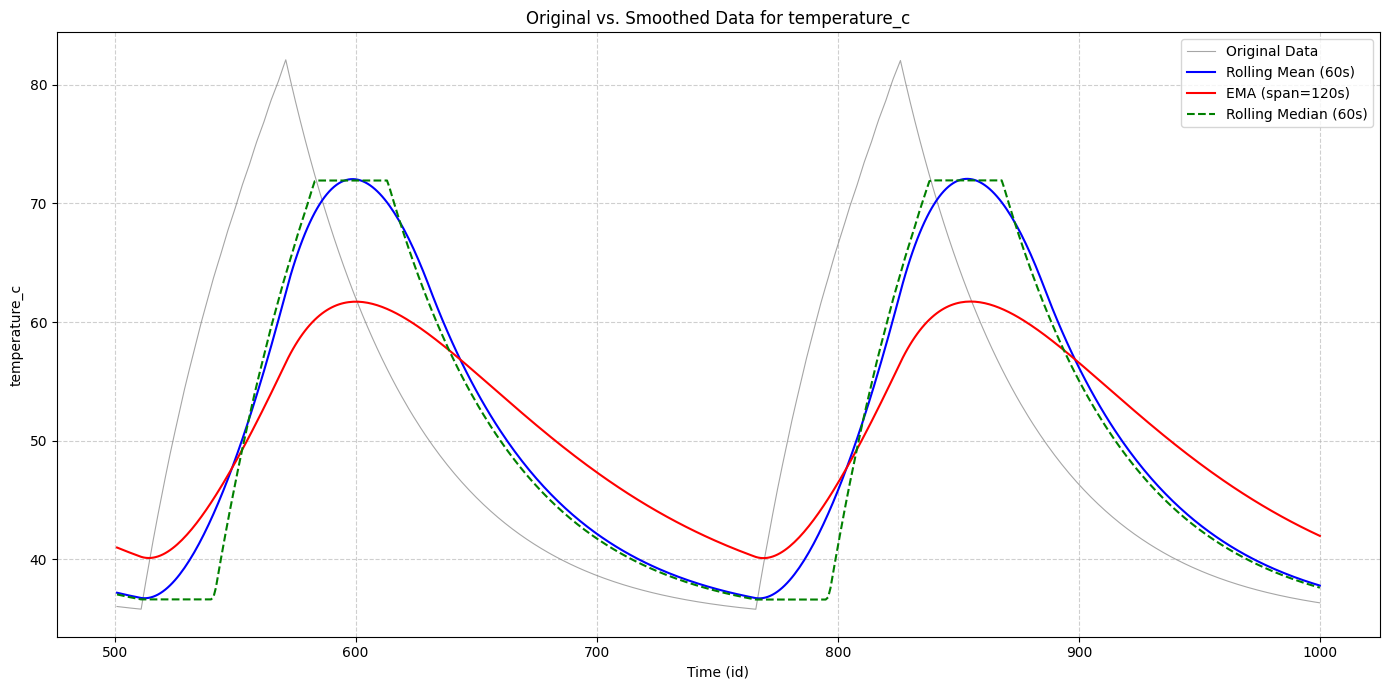


Data smoothing process complete. New smoothed columns have been added to 'df_smoothed'.

Smoothed data saved successfully to 'enhanced_compressor_data_smoothed.csv'


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Load the input dataset ---
try:
    df = pd.read_csv("enhanced_compressor_data_v4_with_ttf.csv")
    print("Dataset loaded successfully.")
    print("Original DataFrame head:")
    print(df[['motor_rpm', 'pressure_bar', 'temperature_c', 'vibration_rms',
       'power_kw', 'airflow_demand_cfm', 'torque_nm', 'noise_db',
       'oilpump_power_w', 'motor_health', 'compressor_health', 'tank_health',
       'blockage_factor', 'leak_rate_lpm', 'load_unload_cycles', 'fault_type',
       'repair_status', 'pressure_change_rate', 'temperature_change_rate',
       'vibration_moving_avg', 'time_since_last_repair', 'id',
       'time_to_failure']].head())
except FileNotFoundError:
    print("Error: File 'enhanced_compressor_data_v4_with_ttf.csv' not found. Please ensure the file is in the correct directory.")
    exit()

# Ensure 'id' column is suitable for sorting (assuming it represents time/sequence)
df = df.sort_values(by='id').reset_index(drop=True)

# --- 2. Define parameters for smoothing ---
# Define the columns you want to smooth
columns_to_smooth = ['pressure_bar', 'temperature_c', 'vibration_rms', 'power_kw']

# Define window sizes for rolling mean/median
rolling_window_size = 60 # e.g., 60 data points (assuming 1-second interval, this is 1 minute)
# Define span for EMA
ema_span = 120 # e.g., 120 data points (assuming 1-second interval, this is 2 minutes)

# --- 3. Apply Smoothing Techniques ---

# Create a copy of the DataFrame to store smoothed data
df_smoothed = df.copy()

print(f"\n--- Applying Smoothing with Window Size: {rolling_window_size} (Rolling) and Span: {ema_span} (EMA) ---")

for col in columns_to_smooth:
    # --- Rolling Mean ---
    df_smoothed[f'{col}_rolling_mean_{rolling_window_size}s'] = df_smoothed[col].rolling(window=rolling_window_size, min_periods=1).mean()
    print(f"Applied rolling mean to: {col}")

    # --- Rolling Median ---
    df_smoothed[f'{col}_rolling_median_{rolling_window_size}s'] = df_smoothed[col].rolling(window=rolling_window_size, min_periods=1).median()
    print(f"Applied rolling median to: {col}")

    # --- Exponential Moving Average (EMA) ---
    df_smoothed[f'{col}_ema_span_{ema_span}s'] = df_smoothed[col].ewm(span=ema_span, adjust=False, min_periods=1).mean()
    print(f"Applied EMA to: {col}")

print("\nSmoothed DataFrame head with new columns:")
print(df_smoothed[['id'] + [c for c in df_smoothed.columns if '_rolling_mean_' in c or '_ema_span_' in c]].head())


# --- 4. Visualize the original vs. smoothed data for a sample column ---
# Let's visualize 'temperature_c'
sample_col = 'temperature_c'
plot_range = df_smoothed['id'].iloc[500:1000] # Plot a segment to clearly see smoothing effects

plt.figure(figsize=(14, 7))
sns.lineplot(x='id', y=sample_col, data=df_smoothed.loc[df_smoothed['id'].isin(plot_range)], label='Original Data', color='gray', alpha=0.7, linewidth=0.8)
sns.lineplot(x='id', y=f'{sample_col}_rolling_mean_{rolling_window_size}s', data=df_smoothed.loc[df_smoothed['id'].isin(plot_range)], label=f'Rolling Mean ({rolling_window_size}s)', color='blue', linewidth=1.5)
sns.lineplot(x='id', y=f'{sample_col}_ema_span_{ema_span}s', data=df_smoothed.loc[df_smoothed['id'].isin(plot_range)], label=f'EMA (span={ema_span}s)', color='red', linewidth=1.5)
sns.lineplot(x='id', y=f'{sample_col}_rolling_median_{rolling_window_size}s', data=df_smoothed.loc[df_smoothed['id'].isin(plot_range)], label=f'Rolling Median ({rolling_window_size}s)', color='green', linestyle='--', linewidth=1.5)

plt.title(f'Original vs. Smoothed Data for {sample_col}')
plt.xlabel('Time (id)')
plt.ylabel(sample_col)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("\nData smoothing process complete. New smoothed columns have been added to 'df_smoothed'.")


# --- 5. Save the smoothed DataFrame to a new CSV file ---
output_filename = "enhanced_compressor_data_smoothed.csv"
df_smoothed.to_csv(output_filename, index=False) # index=False prevents pandas from writing the DataFrame index as a column
print(f"\nSmoothed data saved successfully to '{output_filename}'")

Applying feature engineering to training data...


<ipython-input-2-40d1b8cc488b>:64: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_df = data_df.fillna(method='bfill').fillna(0)


Applying feature engineering to test data...


<ipython-input-2-40d1b8cc488b>:64: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_df = data_df.fillna(method='bfill').fillna(0)



Data points in training set (0 < TTF <= 7200 seconds): 80000
Data points in test set (0 < TTF <= 7200 seconds): 19368

Calculated Class Weights: {np.int64(0): np.float64(1.5), np.int64(1): np.float64(1.0), np.int64(2): np.float64(1.5), np.int64(3): np.float64(1.0)}

Distribution of RUL Classes in Resampled Training Set:
rul_class
0    38900
1    38900
2    38900
3    38900
Name: count, dtype: int64

Training XGBoost model with manually selected parameters...

Training finished using the best model.

--- Multi-class Classification Performance (Original Test Set, RUL 0-7200 seconds) ---
Overall Accuracy: 0.970

Classification Report:
              precision    recall  f1-score   support

    0-10 min       1.00      1.00      1.00      2193
   10-30 min       0.96      1.00      0.98      9725
   30-60 min       0.97      0.93      0.95      6059
  60-120 min       0.97      0.91      0.94      1391

    accuracy                           0.97     19368
   macro avg       0.97      0.96

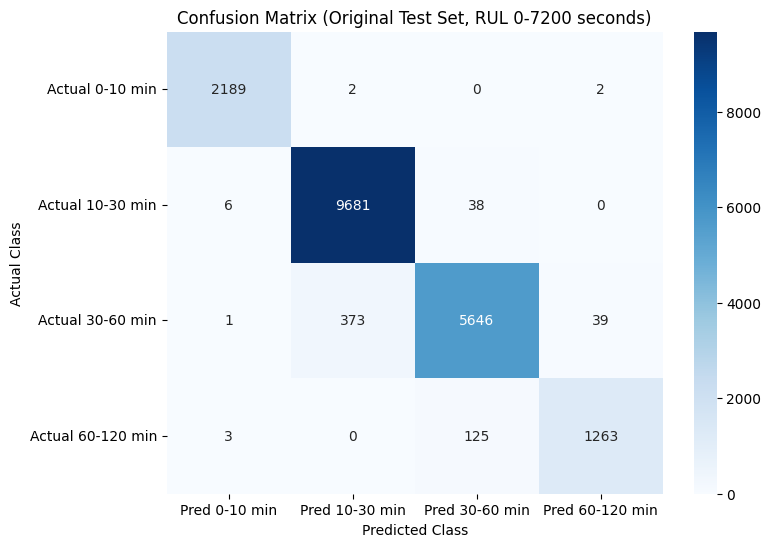


--- Sample of Multi-class Predictions (Original Test Set, RUL 0-7200 seconds) ---
     time_dhms  actual_rul_class  predicted_rul_class  actual_ttf_seconds  \
0   0:22:13:21                 2                    2              2704.0   
1   0:22:13:22                 2                    2              2703.0   
2   0:22:13:23                 2                    2              2702.0   
3   0:22:13:24                 2                    2              2701.0   
4   0:22:13:25                 2                    2              2700.0   
5   0:22:13:26                 2                    2              2699.0   
6   0:22:13:27                 2                    2              2698.0   
7   0:22:13:28                 2                    2              2697.0   
8   0:22:13:29                 2                    2              2696.0   
9   0:22:13:30                 2                    2              2695.0   
10  0:22:13:31                 2                    2              269

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import class_weight
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from imblearn.over_sampling import SMOTE
import pickle
import shap
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# Function to convert seconds to days:hours:minutes:seconds format
def seconds_to_dhms(seconds):
    if pd.isna(seconds) or seconds < 0:
        return "N/A"
    days = int(seconds // (24 * 3600))
    seconds %= 24 * 3600
    hours = int(seconds // 3600)
    seconds %= 3600
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{days}:{hours:02d}:{minutes:02d}:{seconds:02d}"

# Function to create derived features with rolling windows in seconds
def create_features(data_df):
    data_df = data_df.sort_values(by='id').reset_index(drop=True)
    data_df = data_df.copy()
    epsilon = 1e-8  # Avoid division by zero
    window_sizes_points = [300, 600, 1200, 2400, 3000, 3600, 4800]

    core_features = ['pressure_bar', 'temperature_c', 'vibration_rms', 'power_kw']

    for window_size in window_sizes_points:
        if window_size > len(data_df):
            print(f"Warning: Window size {window_size} is larger than dataset length ({len(data_df)}). Skipping.")
            continue
        for col in core_features:
            data_df[f'{col}_mean_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).mean()
            data_df[f'{col}_std_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).std()
            data_df[f'{col}_min_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).min()
            data_df[f'{col}_max_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).max()
            if window_size > 2:
                data_df[f'{col}_skew_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).skew()
                data_df[f'{col}_kurt_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).kurt()
        for col in core_features:
            data_df[f'{col}_diff_{window_size}sec'] = data_df[col].diff(periods=window_size)
            data_df[f'time_diff_{window_size}sec'] = data_df['id'].diff(periods=window_size)
            data_df[f'{col}_change_rate_{window_size}sec'] = data_df[f'{col}_diff_{window_size}sec'] / (data_df[f'time_diff_{window_size}sec'] + epsilon)
            data_df = data_df.drop(columns=[f'{col}_diff_{window_size}sec', f'time_diff_{window_size}sec'], errors='ignore')

    # Add EMA feature for 7200 seconds
    for col in core_features:
        data_df[f'{col}_ema_120sec'] = data_df[col].ewm(span=120, adjust=False).mean()
        data_df[f'{col}_ema_2000sec'] = data_df[col].ewm(span=1970, adjust=False).mean()
        data_df[f'{col}_ema_3370sec'] = data_df[col].ewm(span=3370, adjust=False).mean()
        data_df[f'{col}_ema_7200sec'] = data_df[col].ewm(span=7200, adjust=False).mean()

    data_df = data_df.fillna(method='bfill').fillna(0)
    return data_df

# Function to map time_to_failure to RUL classes
def map_ttf_to_class(ttf):
    if pd.isna(ttf) or ttf <= 0 or ttf > 7200:
        return -1
    elif ttf <= 60:
        return 0  # 0 < TTF <= 600 seconds
    elif ttf <= 2005:
        return 1  # 600 < TTF <= 1800 seconds
    elif ttf <= 3345:
        return 2  # 1800 < TTF <= 3600 seconds
    elif ttf <= 7200:
        return 3  # 3600 < TTF <= 7200 seconds
    else:
        return -1

# Load the dataset
try:
    df = pd.read_csv("enhanced_compressor_data_v4_with_ttf.csv")
except FileNotFoundError:
    print("Error: File 'enhanced_compressor_data_v4_with_ttf.csv' not found.")
    exit()

# Verify 'id' and 'time_to_failure' columns
if 'id' not in df.columns or 'time_to_failure' not in df.columns:
    raise ValueError("Required columns ('id', 'time_to_failure') not found.")
df.dropna(subset=['time_to_failure'], inplace=True)

# Sort by 'id' and reset index
df = df.sort_values(by='id').reset_index(drop=True)

# Step 1: Split data temporally (80/20)
train_size_ratio = 0.8
train_size_index = int(train_size_ratio * len(df))
train_df = df.iloc[:train_size_index].copy()
test_df = df.iloc[train_size_index:].copy()

# Step 2: Apply feature engineering
print("Applying feature engineering to training data...")
train_df = create_features(train_df)
print("Applying feature engineering to test data...")
test_df = create_features(test_df)

# Step 3: Assign RUL classes
max_classification_ttf = 7200.0
train_df['rul_class'] = train_df['time_to_failure'].apply(map_ttf_to_class)
test_df['rul_class'] = test_df['time_to_failure'].apply(map_ttf_to_class)

# Filter data to keep valid RUL classes
train_df_filtered = train_df[(train_df['rul_class'] != -1) & (train_df['time_to_failure'] > 0)].copy()
test_df_filtered = test_df[(test_df['rul_class'] != -1) & (test_df['time_to_failure'] > 0)].copy()

print(f"\nData points in training set (0 < TTF <= {int(max_classification_ttf)} seconds): {len(train_df_filtered)}")
print(f"Data points in test set (0 < TTF <= {int(max_classification_ttf)} seconds): {len(test_df_filtered)}")

if len(train_df_filtered) == 0 or len(test_df_filtered) == 0:
    raise ValueError("Not enough data points in the specified TTF range for classification.")

# Step 4: Define features and target
exclude_cols = ['id', 'fault_type', 'time_to_failure', 'is_failure', 'rul_class', 'is_failure_soon', 'motor_health',
                'compressor_health', 'tank_health', 'blockage_factor', 'leak_rate_lpm', 'load_unload_cycles', 'time_since_last_repair']
features = [col for col in train_df_filtered.columns if col not in exclude_cols]
features = [f for f in features if not any(sub in f for sub in ['_short', '_long', '_diff'])]

X_train = train_df_filtered[features]
y_train = train_df_filtered['rul_class']
X_test = test_df_filtered[features]
y_test = test_df_filtered['rul_class']
# Step 5: Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 6: Oversample training set with SMOTE
smote = SMOTE(random_state=42)
X_train_scaled_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# Step 7: Compute class weights for resampled training data
classes = np.unique(y_train_resampled)
if len(classes) != 4:
    print(f"Warning: Found {len(classes)} unique classes in training data, expected 4.")
    print(f"Classes found: {classes}")
weights = class_weight.compute_class_weight('balanced', classes=classes, y=y_train_resampled)
class_weights = dict(zip(classes, weights))
class_weights[0] *= 1.5  # Increase weight for class 0 by 50%
class_weights[2] *= 1.5  # Increase weight for class 2 by 50%
print("\nCalculated Class Weights:", class_weights)
print("\nDistribution of RUL Classes in Resampled Training Set:")
print(pd.Series(y_train_resampled).value_counts().sort_index())

# Step 8: Train XGBoost model with fixed parameters
fixed_params = {
    'n_estimators': 100,
    'max_depth': 25,
    'learning_rate': 0.1,
    'subsample': 0.7,
    'colsample_bytree': 0.7,
    'min_child_weight': 3,
    'gamma': 0.1,
    'reg_alpha': 0.01,
    'reg_lambda': 0.001
}

best_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=len(classes),
    random_state=42,
    eval_metric='mlogloss',
    **fixed_params
)

print("\nTraining XGBoost model with manually selected parameters...")
best_model.fit(X_train_scaled_resampled, y_train_resampled,
               sample_weight=np.array([class_weights[i] for i in y_train_resampled]))
print("\nTraining finished using the best model.")

# Step 9: Evaluate on original test set
y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)

# Dynamically set class_names based on unique classes in y_test
unique_classes = np.unique(y_test)
class_names = [
    '0-10 min' if 0 in unique_classes else None,
    '10-30 min' if 1 in unique_classes else None,
    '30-60 min' if 2 in unique_classes else None,
    '60-120 min' if 3 in unique_classes else None
]
class_names = [name for name in class_names if name is not None]

print(f"\n--- Multi-class Classification Performance (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds) ---")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names, labels=unique_classes))

cm = confusion_matrix(y_test, y_pred, labels=unique_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'Pred {name}' for name in class_names],
            yticklabels=[f'Actual {name}' for name in class_names])
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title(f'Confusion Matrix (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds)')
plt.show()

# Step 10: Oversample test set for balanced evaluation
smote_test = SMOTE(random_state=42)
X_test_scaled_resampled, y_test_resampled = smote_test.fit_resample(X_test_scaled, y_test)

# Predict on resampled test set
y_pred_resampled = best_model.predict(X_test_scaled_resampled)
y_pred_proba_resampled = best_model.predict_proba(X_test_scaled_resampled)

# Step 11: Analyze predictions on original test set
test_df_results = test_df_filtered.copy().reset_index(drop=True)
test_df_results['predicted_rul_class'] = y_pred
test_df_results['actual_rul_class'] = y_test.values
test_df_results['predicted_proba'] = [y_pred_proba[i, predicted_class] for i, predicted_class in enumerate(y_pred)]
test_df_results['actual_ttf_seconds'] = test_df_filtered['time_to_failure'].values
test_df_results['time_dhms'] = test_df_results['id'].apply(seconds_to_dhms)

print(f"\n--- Sample of Multi-class Predictions (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds) ---")
print(test_df_results[['time_dhms', 'actual_rul_class', 'predicted_rul_class', 'actual_ttf_seconds', 'predicted_proba']].head(20))

# Analyze warnings (RUL <= 3600 seconds)
warning_classes = [0, 1, 2]
warning_classes_names = ['0-600 sec', '600-1800 sec', '1800-3600 sec']
warning_schedule_analysis = test_df_results[test_df_results['predicted_rul_class'].isin(warning_classes)].copy()

if not warning_schedule_analysis.empty:
    print(f"\n--- Analysis for Warnings Triggered (Predicted RUL {warning_classes_names}: 0-3600 seconds) ---")
    print("Actual RUL (seconds) distribution when a warning is triggered:")
    print(warning_schedule_analysis['actual_ttf_seconds'].describe())
    true_positives_warnings = warning_schedule_analysis[warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    false_positives_warnings = warning_schedule_analysis[~warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    print(f"\nBreakdown of Warnings:")
    print(f"Total Warnings Triggered: {len(warning_schedule_analysis)}")
    if len(warning_schedule_analysis) > 0:
        print(f"  True Warnings (Actual RUL <= 3600 secs): {len(true_positives_warnings)} ({len(true_positives_warnings)/len(warning_schedule_analysis):.1%})")
        print(f"  False Warnings (Actual RUL > 3600 secs): {len(false_positives_warnings)} ({len(false_positives_warnings)/len(warning_schedule_analysis):.1%})")
        if not false_positives_warnings.empty:
            print("  Actual RUL (seconds) for False Warnings:")
            print(false_positives_warnings['actual_ttf_seconds'].describe())
    actual_failures_in_warning_range = test_df_results[test_df_results['actual_rul_class'].isin(warning_classes)]
    missed_warnings = actual_failures_in_warning_range[~actual_failures_in_warning_range['predicted_rul_class'].isin(warning_classes)]
    print(f"\nAnalysis of Missed Warnings (Actual RUL <= 3600 secs):")
    print(f"Total Actual Failure points in 0-3600 sec range: {len(actual_failures_in_warning_range)}")
    if len(actual_failures_in_warning_range) > 0:
        print(f"  Missed Warnings: {len(missed_warnings)} ({len(missed_warnings)/len(actual_failures_in_warning_range):.1%})")
        if not missed_warnings.empty:
            print("  Actual RUL (seconds) for Missed Warnings:")
            print(missed_warnings['actual_ttf_seconds'].describe())
else:
    print(f"\nNo warnings triggered based on Predicted RUL {warning_classes_names}.")


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import class_weight
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from imblearn.over_sampling import SMOTE
import pickle
import shap
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# Function to convert seconds to days:hours:minutes:seconds format
def seconds_to_dhms(seconds):
    if pd.isna(seconds) or seconds < 0:
        return "N/A"
    days = int(seconds // (24 * 3600))
    seconds %= 24 * 3600
    hours = int(seconds // 3600)
    seconds %= 3600
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{days}:{hours:02d}:{minutes:02d}:{seconds:02d}"

# Function to create derived features with rolling windows in seconds
def create_features(data_df):
    data_df = data_df.sort_values(by='id').reset_index(drop=True)
    data_df = data_df.copy()
    epsilon = 1e-8  # Avoid division by zero
    window_sizes_points = [300, 600, 1200, 2400, 3000, 3600, 4800]

    core_features = ['pressure_bar', 'temperature_c', 'vibration_rms', 'power_kw']

    for window_size in window_sizes_points:
        if window_size > len(data_df):
            print(f"Warning: Window size {window_size} is larger than dataset length ({len(data_df)}). Skipping.")
            continue
        for col in core_features:
            data_df[f'{col}_mean_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).mean()
            data_df[f'{col}_std_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).std()
            data_df[f'{col}_min_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).min()
            data_df[f'{col}_max_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).max()
            if window_size > 2:
                data_df[f'{col}_skew_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).skew()
                data_df[f'{col}_kurt_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).kurt()
        for col in core_features:
            data_df[f'{col}_diff_{window_size}sec'] = data_df[col].diff(periods=window_size)
            data_df[f'time_diff_{window_size}sec'] = data_df['id'].diff(periods=window_size)
            data_df[f'{col}_change_rate_{window_size}sec'] = data_df[f'{col}_diff_{window_size}sec'] / (data_df[f'time_diff_{window_size}sec'] + epsilon)
            data_df = data_df.drop(columns=[f'{col}_diff_{window_size}sec', f'time_diff_{window_size}sec'], errors='ignore')

    # Add EMA feature for 7200 seconds
    for col in core_features:
        data_df[f'{col}_ema_7200sec'] = data_df[col].ewm(span=7200, adjust=False).mean()

    data_df = data_df.fillna(method='bfill').fillna(0)
    return data_df

# Function to map time_to_failure to RUL classes
def map_ttf_to_class(ttf):
    if pd.isna(ttf) or ttf <= 0 or ttf > 7200:
        return -1
    elif ttf <= 600:
        return 0  # 0 < TTF <= 600 seconds
    elif ttf <= 1800:
        return 1  # 600 < TTF <= 1800 seconds
    elif ttf <= 3600:
        return 2  # 1800 < TTF <= 3600 seconds
    elif ttf <= 7200:
        return 3  # 3600 < TTF <= 7200 seconds
    else:
        return -1
# Load the dataset
try:
    df = pd.read_csv("compressor_data_with_rul_labels.csv")
except FileNotFoundError:
    exit()
# Verify 'id' and 'time_to_failure' columns
if 'id' not in df.columns or 'time_to_failure' not in df.columns:
    raise ValueError("Required columns ('id', 'time_to_failure') not found.")
df.dropna(subset=['time_to_failure'], inplace=True)

df = df.sort_values(by='id').reset_index(drop=True)
# Split data temporally (80/20)
train_size_ratio = 0.8
train_size_index = int(train_size_ratio * len(df))
train_df = df.iloc[:train_size_index].copy()
test_df = df.iloc[train_size_index:].copy()
# Apply feature engineering
train_df = create_features(train_df)
test_df = create_features(test_df)
# Assign RUL classes
max_classification_ttf = 7200.0
train_df['rul_class'] = train_df['time_to_failure'].apply(map_ttf_to_class)
test_df['rul_class'] = test_df['time_to_failure'].apply(map_ttf_to_class)

# Filter data to keep valid RUL classes
train_df_filtered = train_df[(train_df['rul_class'] != -1) & (train_df['time_to_failure'] > 0)].copy()
test_df_filtered = test_df[(test_df['rul_class'] != -1) & (test_df['time_to_failure'] > 0)].copy()

if len(train_df_filtered) == 0 or len(test_df_filtered) == 0:
    raise ValueError("Not enough data points in the specified TTF range for classification.")

# Define features and target
exclude_cols = ['id', 'fault_type', 'time_to_failure', 'is_failure', 'rul_class', 'is_failure_soon', 'motor_health',
                'compressor_health', 'tank_health', 'blockage_factor', 'leak_rate_lpm', 'load_unload_cycles', 'time_since_last_repair', 'repair_status']
features = [col for col in train_df_filtered.columns if col not in exclude_cols]
features = [f for f in features if not any(sub in f for sub in ['_short', '_long', '_diff'])]

X_train = train_df_filtered[features]
y_train = train_df_filtered['rul_class']
X_test = test_df_filtered[features]
y_test = test_df_filtered['rul_class']
# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Oversample training set with SMOTE
smote = SMOTE(random_state=42)
X_train_scaled_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)
#Compute class weights for resampled training data
classes = np.unique(y_train_resampled)
if len(classes) != 4:
    print(f"Warning: Found {len(classes)} unique classes in training data, expected 4.")
    print(f"Classes found: {classes}")
weights = class_weight.compute_class_weight('balanced', classes=classes, y=y_train_resampled)
class_weights = dict(zip(classes, weights))
class_weights[0] *= 1.5  # Increase weight for class 0 by 50%
class_weights[2] *= 1.5  # Increase weight for class 2 by 50%
# Train XGBoost model with RandomizedSearchCV
base_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=len(classes),
    random_state=42,
    eval_metric='mlogloss'
)
param_dist = {
    'n_estimators': [50, 100, 200, 1000, 1500],
    'max_depth': [10, 15, 25, 30],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.7, 0.8, 0.9],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9],
    'min_child_weight': [1, 3, 5],
    'gamma': [0.0, 0.1, 0.2],
    'reg_alpha': [0.001, 0.01, 0.1],
    'reg_lambda': [0.0001, 0.001, 0.01]
}
random_search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_dist,
    n_iter=50,
    scoring='f1_weighted',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_scaled_resampled, y_train_resampled,
                 sample_weight=np.array([class_weights[i] for i in y_train_resampled]))
best_model = random_search.best_estimator_
# Evaluate on original test set
y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)
# Dynamically set class_names based on unique classes in y_test
unique_classes = np.unique(y_test)
class_names = [
    '0-10 min' if 0 in unique_classes else None,
    '10-30 min' if 1 in unique_classes else None,
    '30-60 min' if 2 in unique_classes else None,
    '60-120 min' if 3 in unique_classes else None
]
class_names = [name for name in class_names if name is not None]
cm = confusion_matrix(y_test, y_pred, labels=unique_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'Pred {name}' for name in class_names],
            yticklabels=[f'Actual {name}' for name in class_names])
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title(f'Confusion Matrix (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds)')
plt.savefig('confusion_matrix.png')
plt.close()
# Oversample test set for balanced evaluation
smote_test = SMOTE(random_state=42)
X_test_scaled_resampled, y_test_resampled = smote_test.fit_resample(X_test_scaled, y_test)
# Predict on resampled test set
y_pred_resampled = best_model.predict(X_test_scaled_resampled)
y_pred_proba_resampled = best_model.predict_proba(X_test_scaled_resampled)
# Analyze predictions on original test set
test_df_results = test_df_filtered.copy().reset_index(drop=True)
test_df_results['predicted_rul_class'] = y_pred
test_df_results['actual_rul_class'] = y_test.values
test_df_results['predicted_proba'] = [y_pred_proba[i, predicted_class] for i, predicted_class in enumerate(y_pred)]
test_df_results['actual_ttf_seconds'] = test_df_filtered['time_to_failure'].values
test_df_results['time_dhms'] = test_df_results['id'].apply(seconds_to_dhms)

print(test_df_results[['time_dhms', 'actual_rul_class', 'predicted_rul_class', 'actual_ttf_seconds', 'predicted_proba']].head(20))

# Analyze warnings (RUL <= 3600 seconds)
warning_classes = [0, 1, 2]
warning_classes_names = ['0-600 sec', '600-1800 sec', '1800-3600 sec']
warning_schedule_analysis = test_df_results[test_df_results['predicted_rul_class'].isin(warning_classes)].copy()

if not warning_schedule_analysis.empty:
    print("Actual RUL (seconds) distribution when a warning is triggered:")
    print(warning_schedule_analysis['actual_ttf_seconds'].describe())
    true_positives_warnings = warning_schedule_analysis[warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    false_positives_warnings = warning_schedule_analysis[~warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    if len(warning_schedule_analysis) > 0:
        print(f"  True Warnings (Actual RUL <= 3600 secs): {len(true_positives_warnings)} ({len(true_positives_warnings)/len(warning_schedule_analysis):.1%})")
        print(f"  False Warnings (Actual RUL > 3600 secs): {len(false_positives_warnings)} ({len(false_positives_warnings)/len(warning_schedule_analysis):.1%})")
        if not false_positives_warnings.empty:
            print("  Actual RUL (seconds) for False Warnings:")
            print(false_positives_warnings['actual_ttf_seconds'].describe())
    actual_failures_in_warning_range = test_df_results[test_df_results['actual_rul_class'].isin(warning_classes)]
    missed_warnings = actual_failures_in_warning_range[~actual_failures_in_warning_range['predicted_rul_class'].isin(warning_classes)]
    print(f"\nAnalysis of Missed Warnings (Actual RUL <= 3600 secs):")
    print(f"Total Actual Failure points in 0-3600 sec range: {len(actual_failures_in_warning_range)}")
    if len(actual_failures_in_warning_range) > 0:
        print(f"  Missed Warnings: {len(missed_warnings)} ({len(missed_warnings)/len(actual_failures_in_warning_range):.1%})")
        if not missed_warnings.empty:
            print("  Actual RUL (seconds) for Missed Warnings:")
            print(missed_warnings['actual_ttf_seconds'].describe())
else:
    print(f"\nNo warnings triggered based on Predicted RUL {warning_classes_names}.")
#Save model, scaler, features, and test data
best_model.save_model(f'xgboost_multiclass_rul_prediction_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.json')
print(f"\nXGBoost Multi-class RUL Prediction model saved.")
joblib.dump(scaler, f'scaler_multiclass_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.pkl')
print("Scaler saved successfully.")
with open(f'features_list_ttf_{int(max_classification_ttf)}sec.pkl', 'wb') as f:
    pickle.dump(features, f)
print("Features list saved successfully.")
with open(f'test_data_ttf_{int(max_classification_ttf)}sec.pkl', 'wb') as f:
    pickle.dump((X_test_scaled, y_test), f)


Applying feature engineering to training data...


<ipython-input-1-4ad94af19d9f>:64: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_df = data_df.fillna(method='bfill').fillna(0)


Applying feature engineering to test data...


<ipython-input-1-4ad94af19d9f>:64: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_df = data_df.fillna(method='bfill').fillna(0)



Data points in training set (0 < TTF <= 7200 seconds): 80000
Data points in test set (0 < TTF <= 7200 seconds): 19368

Calculated Class Weights: {np.int64(0): np.float64(1.5), np.int64(1): np.float64(1.0), np.int64(2): np.float64(1.5), np.int64(3): np.float64(1.0)}

Distribution of RUL Classes in Resampled Training Set:
rul_class
0    38900
1    38900
2    38900
3    38900
Name: count, dtype: int64

Training XGBoost model with manually selected parameters...

Training finished using the best model.

--- Multi-class Classification Performance (Original Test Set, RUL 0-7200 seconds) ---
Overall Accuracy: 0.969

Classification Report:
              precision    recall  f1-score   support

    0-10 min       1.00      0.99      0.99      2193
   10-30 min       0.96      1.00      0.98      9725
   30-60 min       0.98      0.93      0.95      6059
  60-120 min       0.96      0.91      0.93      1391

    accuracy                           0.97     19368
   macro avg       0.97      0.96

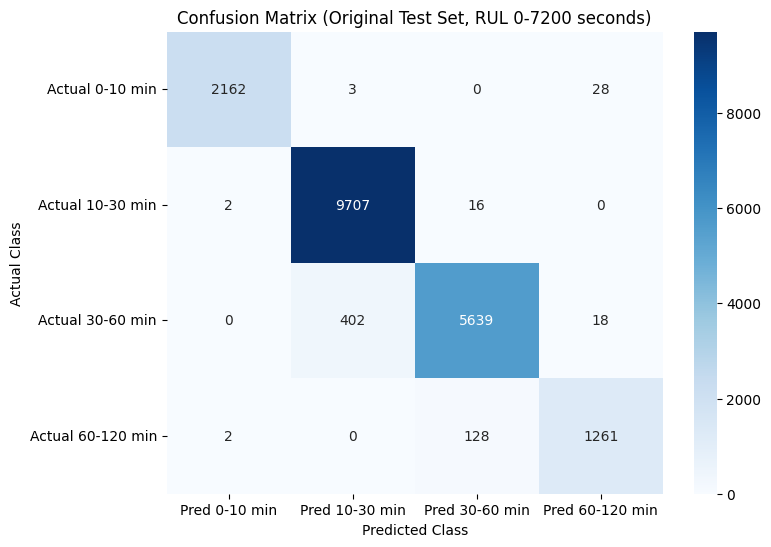


--- Sample of Multi-class Predictions (Original Test Set, RUL 0-7200 seconds) ---
     time_dhms  actual_rul_class  predicted_rul_class  actual_ttf_seconds  \
0   0:22:13:21                 2                    2              2704.0   
1   0:22:13:22                 2                    2              2703.0   
2   0:22:13:23                 2                    2              2702.0   
3   0:22:13:24                 2                    2              2701.0   
4   0:22:13:25                 2                    2              2700.0   
5   0:22:13:26                 2                    2              2699.0   
6   0:22:13:27                 2                    2              2698.0   
7   0:22:13:28                 2                    2              2697.0   
8   0:22:13:29                 2                    2              2696.0   
9   0:22:13:30                 2                    2              2695.0   
10  0:22:13:31                 2                    2              269

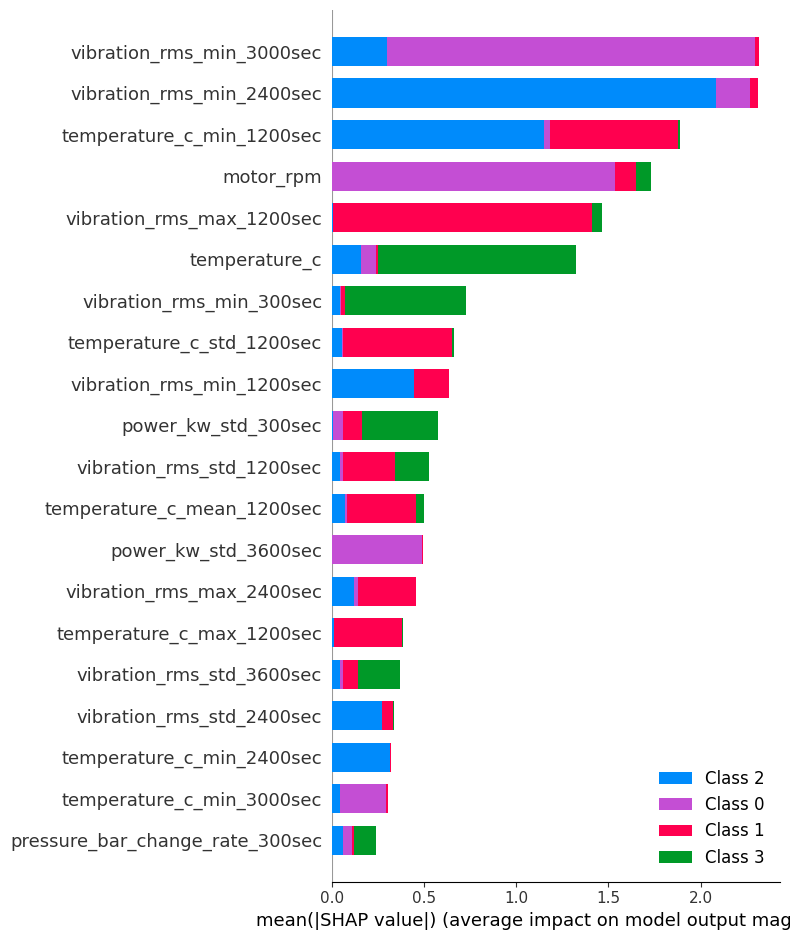

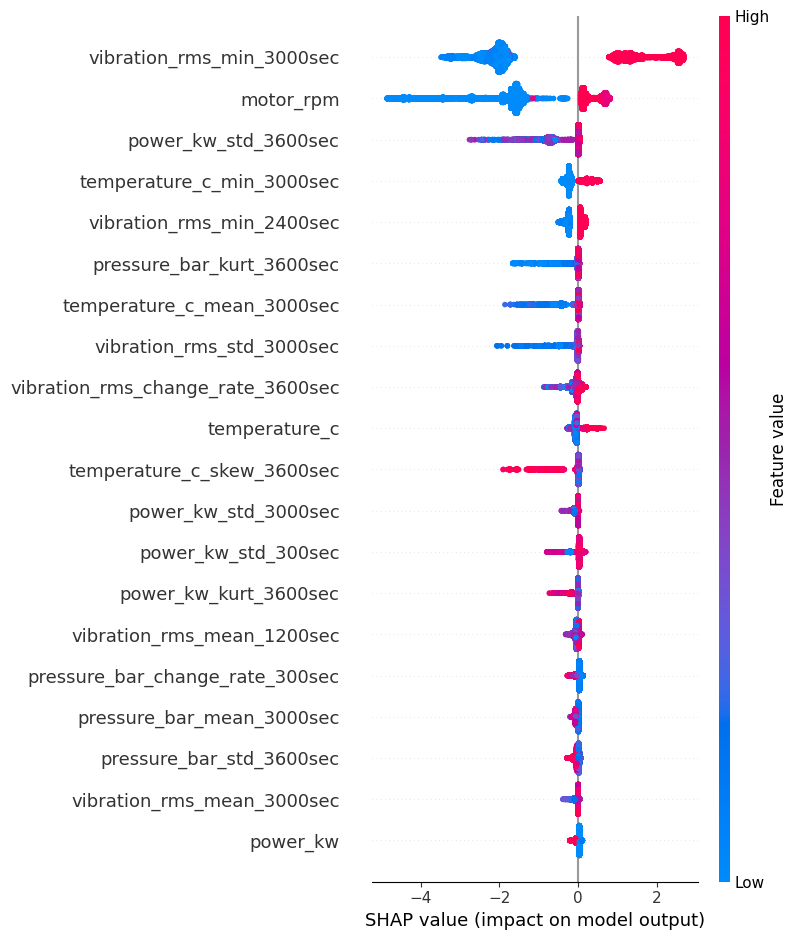

Mean SHAP Impact for Each Time Window Across Classes:
                       0         1         2         3
Window_300sec   0.010282  0.011243  0.014056  0.063633
Window_600sec   0.022010  0.013282  0.006501  0.018972
Window_1200sec  0.006300  0.157422  0.075270  0.017726
Window_2400sec  0.010244  0.022145  0.108066  0.004640
Window_3000sec  0.096656  0.006370  0.017971  0.004617
Window_3600sec  0.040020  0.016725  0.005475  0.017963
Window_4800sec  0.005387  0.001813  0.005909  0.009585


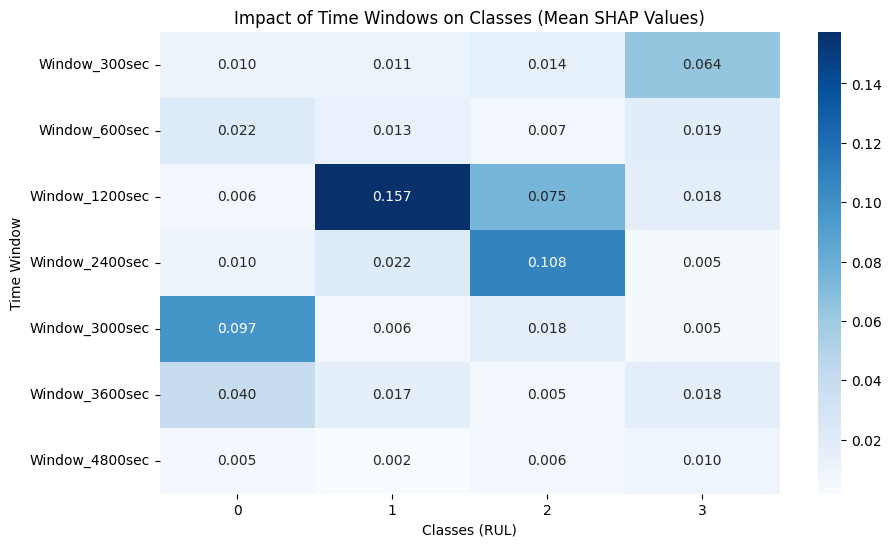


Performing Permutation Importance Analysis...


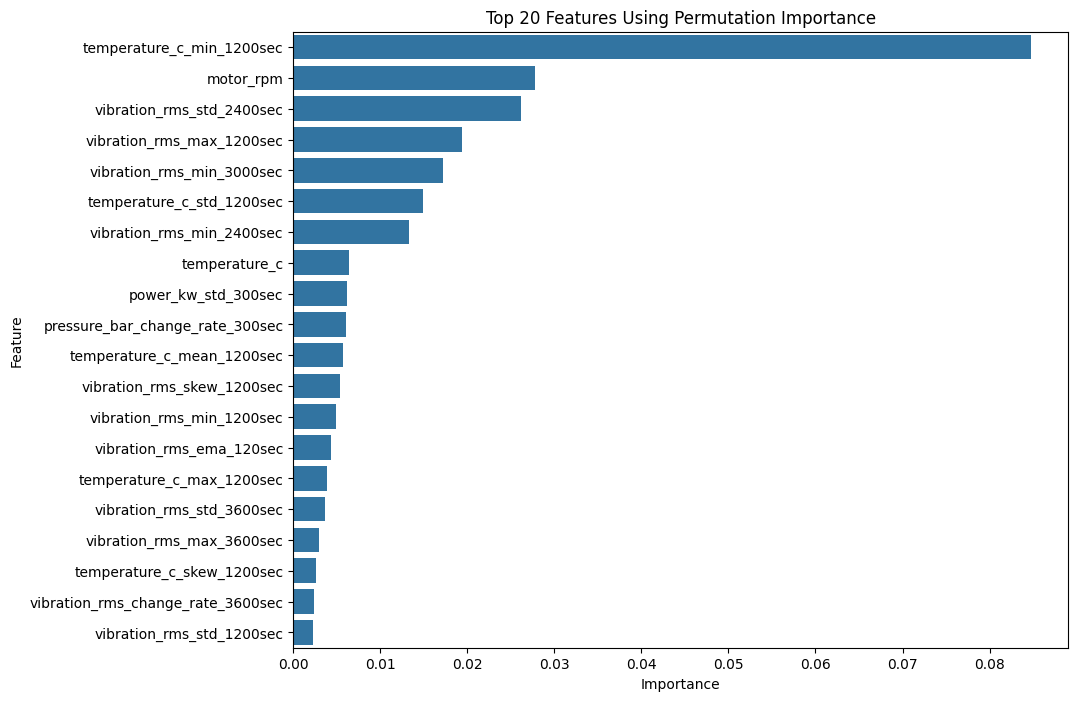


XGBoost Multi-class RUL Prediction model saved.
Scaler saved successfully.
Features list saved successfully.
Test data (X_test_scaled, y_test) saved successfully.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import class_weight
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from imblearn.over_sampling import SMOTE
import pickle
import shap
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# Function to convert seconds to days:hours:minutes:seconds format
def seconds_to_dhms(seconds):
    if pd.isna(seconds) or seconds < 0:
        return "N/A"
    days = int(seconds // (24 * 3600))
    seconds %= 24 * 3600
    hours = int(seconds // 3600)
    seconds %= 3600
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{days}:{hours:02d}:{minutes:02d}:{seconds:02d}"

# Function to create derived features with rolling windows in seconds
def create_features(data_df):
    data_df = data_df.sort_values(by='id').reset_index(drop=True)
    data_df = data_df.copy()
    epsilon = 1e-8  # Avoid division by zero
    window_sizes_points = [300, 600, 1200, 2400, 3000, 3600, 4800]

    core_features = ['pressure_bar', 'temperature_c', 'vibration_rms', 'power_kw']

    for window_size in window_sizes_points:
        if window_size > len(data_df):
            print(f"Warning: Window size {window_size} is larger than dataset length ({len(data_df)}). Skipping.")
            continue
        for col in core_features:
            data_df[f'{col}_mean_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).mean()
            data_df[f'{col}_std_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).std()
            data_df[f'{col}_min_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).min()
            data_df[f'{col}_max_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).max()
            if window_size > 2:
                data_df[f'{col}_skew_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).skew()
                data_df[f'{col}_kurt_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).kurt()
        for col in core_features:
            data_df[f'{col}_diff_{window_size}sec'] = data_df[col].diff(periods=window_size)
            data_df[f'time_diff_{window_size}sec'] = data_df['id'].diff(periods=window_size)
            data_df[f'{col}_change_rate_{window_size}sec'] = data_df[f'{col}_diff_{window_size}sec'] / (data_df[f'time_diff_{window_size}sec'] + epsilon)
            data_df = data_df.drop(columns=[f'{col}_diff_{window_size}sec', f'time_diff_{window_size}sec'], errors='ignore')

    # Add EMA feature for 7200 seconds
    for col in core_features:
        data_df[f'{col}_ema_120sec'] = data_df[col].ewm(span=120, adjust=False).mean()
        data_df[f'{col}_ema_2000sec'] = data_df[col].ewm(span=1970, adjust=False).mean()
        data_df[f'{col}_ema_3370sec'] = data_df[col].ewm(span=3370, adjust=False).mean()
        data_df[f'{col}_ema_7200sec'] = data_df[col].ewm(span=7200, adjust=False).mean()

    data_df = data_df.fillna(method='bfill').fillna(0)
    return data_df

# Function to map time_to_failure to RUL classes
def map_ttf_to_class(ttf):
    if pd.isna(ttf) or ttf <= 0 or ttf > 7200:
        return -1
    elif ttf <= 60:
        return 0  # 0 < TTF <= 600 seconds
    elif ttf <= 2005:
        return 1  # 600 < TTF <= 1800 seconds
    elif ttf <= 3345:
        return 2  # 1800 < TTF <= 3600 seconds
    elif ttf <= 7200:
        return 3  # 3600 < TTF <= 7200 seconds
    else:
        return -1

# Load the dataset
try:
    df = pd.read_csv("enhanced_compressor_data_v4_with_ttf.csv")
except FileNotFoundError:
    print("Error: File 'enhanced_compressor_data_v4_with_ttf.csv' not found.")
    exit()

# Verify 'id' and 'time_to_failure' columns
if 'id' not in df.columns or 'time_to_failure' not in df.columns:
    raise ValueError("Required columns ('id', 'time_to_failure') not found.")
df.dropna(subset=['time_to_failure'], inplace=True)

# Sort by 'id' and reset index
df = df.sort_values(by='id').reset_index(drop=True)

# Step 1: Split data temporally (80/20)
train_size_ratio = 0.8
train_size_index = int(train_size_ratio * len(df))
train_df = df.iloc[:train_size_index].copy()
test_df = df.iloc[train_size_index:].copy()

# Step 2: Apply feature engineering
print("Applying feature engineering to training data...")
train_df = create_features(train_df)
print("Applying feature engineering to test data...")
test_df = create_features(test_df)

# Step 3: Assign RUL classes
max_classification_ttf = 7200.0
train_df['rul_class'] = train_df['time_to_failure'].apply(map_ttf_to_class)
test_df['rul_class'] = test_df['time_to_failure'].apply(map_ttf_to_class)

# Filter data to keep valid RUL classes
train_df_filtered = train_df[(train_df['rul_class'] != -1) & (train_df['time_to_failure'] > 0)].copy()
test_df_filtered = test_df[(test_df['rul_class'] != -1) & (test_df['time_to_failure'] > 0)].copy()

print(f"\nData points in training set (0 < TTF <= {int(max_classification_ttf)} seconds): {len(train_df_filtered)}")
print(f"Data points in test set (0 < TTF <= {int(max_classification_ttf)} seconds): {len(test_df_filtered)}")

if len(train_df_filtered) == 0 or len(test_df_filtered) == 0:
    raise ValueError("Not enough data points in the specified TTF range for classification.")

# Step 4: Define features and target
exclude_cols = ['id', 'fault_type', 'time_to_failure', 'is_failure', 'rul_class', 'is_failure_soon', 'motor_health',
                'compressor_health', 'tank_health', 'blockage_factor', 'leak_rate_lpm', 'load_unload_cycles', 'time_since_last_repair']
features = [col for col in train_df_filtered.columns if col not in exclude_cols]
features = [f for f in features if not any(sub in f for sub in ['_short', '_long', '_diff'])]

X_train = train_df_filtered[features]
y_train = train_df_filtered['rul_class']
X_test = test_df_filtered[features]
y_test = test_df_filtered['rul_class']
# Step 5: Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 6: Oversample training set with SMOTE
smote = SMOTE(random_state=42)
X_train_scaled_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# Step 7: Compute class weights for resampled training data
classes = np.unique(y_train_resampled)
if len(classes) != 4:
    print(f"Warning: Found {len(classes)} unique classes in training data, expected 4.")
    print(f"Classes found: {classes}")
weights = class_weight.compute_class_weight('balanced', classes=classes, y=y_train_resampled)
class_weights = dict(zip(classes, weights))
class_weights[0] *= 1.5  # Increase weight for class 0 by 50%
class_weights[2] *= 1.5  # Increase weight for class 2 by 50%
print("\nCalculated Class Weights:", class_weights)
print("\nDistribution of RUL Classes in Resampled Training Set:")
print(pd.Series(y_train_resampled).value_counts().sort_index())

# Step 8: Train XGBoost model with fixed parameters
fixed_params = {
    'n_estimators': 100,
    'max_depth': 25,
    'learning_rate': 0.1,
    'subsample': 0.7,
    'colsample_bytree': 0.7,
    'min_child_weight': 3,
    'gamma': 0.1,
    'reg_alpha': 0.01,
    'reg_lambda': 0.001
}

best_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=len(classes),
    random_state=42,
    eval_metric='mlogloss',
    **fixed_params
)

print("\nTraining XGBoost model with manually selected parameters...")
best_model.fit(X_train_scaled_resampled, y_train_resampled,
               sample_weight=np.array([class_weights[i] for i in y_train_resampled]))
print("\nTraining finished using the best model.")

# Step 9: Evaluate on original test set
y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)

# Dynamically set class_names based on unique classes in y_test
unique_classes = np.unique(y_test)
class_names = [
    '0-10 min' if 0 in unique_classes else None,
    '10-30 min' if 1 in unique_classes else None,
    '30-60 min' if 2 in unique_classes else None,
    '60-120 min' if 3 in unique_classes else None
]
class_names = [name for name in class_names if name is not None]

print(f"\n--- Multi-class Classification Performance (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds) ---")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names, labels=unique_classes))

cm = confusion_matrix(y_test, y_pred, labels=unique_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'Pred {name}' for name in class_names],
            yticklabels=[f'Actual {name}' for name in class_names])
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title(f'Confusion Matrix (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds)')
plt.show()

# Step 10: Oversample test set for balanced evaluation
smote_test = SMOTE(random_state=42)
X_test_scaled_resampled, y_test_resampled = smote_test.fit_resample(X_test_scaled, y_test)

# Predict on resampled test set
y_pred_resampled = best_model.predict(X_test_scaled_resampled)
y_pred_proba_resampled = best_model.predict_proba(X_test_scaled_resampled)

# Step 11: Analyze predictions on original test set
test_df_results = test_df_filtered.copy().reset_index(drop=True)
test_df_results['predicted_rul_class'] = y_pred
test_df_results['actual_rul_class'] = y_test.values
test_df_results['predicted_proba'] = [y_pred_proba[i, predicted_class] for i, predicted_class in enumerate(y_pred)]
test_df_results['actual_ttf_seconds'] = test_df_filtered['time_to_failure'].values
test_df_results['time_dhms'] = test_df_results['id'].apply(seconds_to_dhms)

print(f"\n--- Sample of Multi-class Predictions (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds) ---")
print(test_df_results[['time_dhms', 'actual_rul_class', 'predicted_rul_class', 'actual_ttf_seconds', 'predicted_proba']].head(20))

# Analyze warnings (RUL <= 3600 seconds)
warning_classes = [0, 1, 2]
warning_classes_names = ['0-600 sec', '600-1800 sec', '1800-3600 sec']
warning_schedule_analysis = test_df_results[test_df_results['predicted_rul_class'].isin(warning_classes)].copy()

if not warning_schedule_analysis.empty:
    print(f"\n--- Analysis for Warnings Triggered (Predicted RUL {warning_classes_names}: 0-3600 seconds) ---")
    print("Actual RUL (seconds) distribution when a warning is triggered:")
    print(warning_schedule_analysis['actual_ttf_seconds'].describe())
    true_positives_warnings = warning_schedule_analysis[warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    false_positives_warnings = warning_schedule_analysis[~warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    print(f"\nBreakdown of Warnings:")
    print(f"Total Warnings Triggered: {len(warning_schedule_analysis)}")
    if len(warning_schedule_analysis) > 0:
        print(f"  True Warnings (Actual RUL <= 3600 secs): {len(true_positives_warnings)} ({len(true_positives_warnings)/len(warning_schedule_analysis):.1%})")
        print(f"  False Warnings (Actual RUL > 3600 secs): {len(false_positives_warnings)} ({len(false_positives_warnings)/len(warning_schedule_analysis):.1%})")
        if not false_positives_warnings.empty:
            print("  Actual RUL (seconds) for False Warnings:")
            print(false_positives_warnings['actual_ttf_seconds'].describe())
    actual_failures_in_warning_range = test_df_results[test_df_results['actual_rul_class'].isin(warning_classes)]
    missed_warnings = actual_failures_in_warning_range[~actual_failures_in_warning_range['predicted_rul_class'].isin(warning_classes)]
    print(f"\nAnalysis of Missed Warnings (Actual RUL <= 3600 secs):")
    print(f"Total Actual Failure points in 0-3600 sec range: {len(actual_failures_in_warning_range)}")
    if len(actual_failures_in_warning_range) > 0:
        print(f"  Missed Warnings: {len(missed_warnings)} ({len(missed_warnings)/len(actual_failures_in_warning_range):.1%})")
        if not missed_warnings.empty:
            print("  Actual RUL (seconds) for Missed Warnings:")
            print(missed_warnings['actual_ttf_seconds'].describe())
else:
    print(f"\nNo warnings triggered based on Predicted RUL {warning_classes_names}.")

# Step 12: SHAP Analysis
print("\nPerforming SHAP Analysis...")
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_scaled)

# Convert X_test_scaled to DataFrame for easier handling
X_test = pd.DataFrame(X_test_scaled, columns=features)

# Calculate mean absolute SHAP values to determine feature importance
shap_values_abs = np.abs(shap_values).mean(axis=0)  # Mean SHAP values for each feature across all classes
shap_importance = pd.DataFrame({
    'Feature': features,
    'Mean_Abs_SHAP': shap_values_abs.mean(axis=1)  # Mean across classes
})
shap_importance = shap_importance.sort_values(by='Mean_Abs_SHAP', ascending=False)

# Select top 20 features
top_features = shap_importance['Feature'].head(20).values
top_feature_indices = [features.index(f) for f in top_features]

# Plot SHAP summary for top 20 features
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values[:, top_feature_indices, :],
                  X_test_scaled[:, top_feature_indices],
                  feature_names=top_features,
                  plot_type="bar",
                  title="Feature Importance (SHAP) for Top 20 Features")
plt.show()

# Plot SHAP summary for Class 0 (0-600 seconds)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values[:, :, 0], X_test, feature_names=features,
                  title="Feature Impact on Class 0 (0-600 seconds)")
plt.show()

# Step 13: Analyze time windows
window_sizes_points = [300, 600, 1200, 2400, 3000, 3600, 4800]
grouped_shap_values = {}

for window_size in window_sizes_points:
    # Select features related to the window
    window_features = [f for f in features if f'{window_size}sec' in f]
    window_feature_indices = [features.index(f) for f in window_features]

    # Calculate mean SHAP values for this window
    if window_feature_indices:
        window_shap = np.abs(shap_values[:, window_feature_indices, :]).mean(axis=1)  # Mean across features
        grouped_shap_values[f'Window_{window_size}sec'] = window_shap.mean(axis=0)  # Mean across samples

# Convert to DataFrame for plotting
grouped_shap_df = pd.DataFrame(grouped_shap_values).T
print("Mean SHAP Impact for Each Time Window Across Classes:")
print(grouped_shap_df)

# Plot the impact
plt.figure(figsize=(10, 6))
sns.heatmap(grouped_shap_df, annot=True, cmap='Blues', fmt='.3f')
plt.title("Impact of Time Windows on Classes (Mean SHAP Values)")
plt.xlabel("Classes (RUL)")
plt.ylabel("Time Window")
plt.show()

# Step 14: Permutation Importance
print("\nPerforming Permutation Importance Analysis...")
perm_importance = permutation_importance(best_model, X_test_scaled, y_test,
                                         scoring='f1_weighted', n_repeats=10, random_state=42)

# Display results
perm_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': perm_importance.importances_mean
})
perm_importance_df = perm_importance_df.sort_values(by='Importance', ascending=False)

# Plot top 20 features
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=perm_importance_df.head(20))
plt.title("Top 20 Features Using Permutation Importance")
plt.show()

# Step 15: Optional - Save model, scaler, features, and test data
best_model.save_model(f'xgboost_multiclass_rul_prediction_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.json')
print(f"\nXGBoost Multi-class RUL Prediction model saved.")
joblib.dump(scaler, f'scaler_multiclass_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.pkl')
print("Scaler saved successfully.")
with open(f'features_list_ttf_{int(max_classification_ttf)}sec.pkl', 'wb') as f:
    pickle.dump(features, f)
print("Features list saved successfully.")
with open(f'test_data_ttf_{int(max_classification_ttf)}sec.pkl', 'wb') as f:
    pickle.dump((X_test_scaled, y_test), f)
print("Test data (X_test_scaled, y_test) saved successfully.")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import class_weight
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from imblearn.over_sampling import SMOTE
import pickle
import warnings
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# Function to convert seconds to days:hours:minutes:seconds format
def seconds_to_dhms(seconds):
    if pd.isna(seconds) or seconds < 0:
        return "N/A"
    days = int(seconds // (24 * 3600))
    seconds %= 24 * 3600
    hours = int(seconds // 3600)
    seconds %= 3600
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{days}:{hours:02d}:{minutes:02d}:{seconds:02d}"

# Function to create derived features with rolling windows in seconds
def create_features(data_df):
    data_df = data_df.sort_values(by='id').reset_index(drop=True)
    data_df = data_df.copy()
    epsilon = 1e-8  # Avoid division by zero
    window_sizes_points = [300, 600, 1200, 2400, 3000, 3600, 4800]

    core_features = ['pressure_bar', 'temperature_c', 'vibration_rms', 'power_kw']

    for window_size in window_sizes_points:
        if window_size > len(data_df):
            print(f"Warning: Window size {window_size} is larger than dataset length ({len(data_df)}). Skipping.")
            continue
        for col in core_features:
            # Rolling window statistics
            data_df[f'{col}_mean_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).mean()
            data_df[f'{col}_std_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).std()
            data_df[f'{col}_min_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).min()
            data_df[f'{col}_max_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).max()
            if window_size > 2:
                data_df[f'{col}_skew_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).skew()
                data_df[f'{col}_kurt_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).kurt()
        for col in core_features:
            # Calculate change rates over the window
            data_df[f'{col}_diff_{window_size}sec'] = data_df[col].diff(periods=window_size)
            data_df[f'time_diff_{window_size}sec'] = data_df['id'].diff(periods=window_size)
            data_df[f'{col}_change_rate_{window_size}sec'] = data_df[f'{col}_diff_{window_size}sec'] / (data_df[f'time_diff_{window_size}sec'] + epsilon)
            data_df = data_df.drop(columns=[f'{col}_diff_{window_size}sec', f'time_diff_{window_size}sec'], errors='ignore')

    # Add Exponential Moving Average (EMA) features
    for col in core_features:
        data_df[f'{col}_ema_120sec'] = data_df[col].ewm(span=120, adjust=False).mean()
        data_df[f'{col}_ema_2000sec'] = data_df[col].ewm(span=1970, adjust=False).mean()
        data_df[f'{col}_ema_3370sec'] = data_df[col].ewm(span=3370, adjust=False).mean()
        data_df[f'{col}_ema_7200sec'] = data_df[col].ewm(span=7200, adjust=False).mean()

    # Fill missing values
    data_df = data_df.fillna(method='bfill').fillna(0)
    return data_df

# Function to map time_to_failure to RUL classes
def map_ttf_to_class(ttf):
    if pd.isna(ttf) or ttf <= 0 or ttf > 7200:
        return -1
    elif ttf <= 600:
        return 0  # 0 < TTF <= 600 seconds
    elif ttf <= 1800:
        return 1  # 600 < TTF <= 1800 seconds
    elif ttf <= 3600:
        return 2  # 1800 < TTF <= 3600 seconds
    elif ttf <= 7200:
        return 3  # 3600 < TTF <= 7200 seconds
    else:
        return -1

# Load the dataset
try:
    df = pd.read_csv("enhanced_compressor_data_v4_with_ttf.csv")
except FileNotFoundError:
    print("Error: File 'enhanced_compressor_data_v4_with_ttf.csv' not found.")
    exit()

# Verify 'id' and 'time_to_failure' columns
if 'id' not in df.columns or 'time_to_failure' not in df.columns:
    raise ValueError("Required columns ('id', 'time_to_failure') not found.")
df.dropna(subset=['time_to_failure'], inplace=True)

# Sort by 'id' and reset index
df = df.sort_values(by='id').reset_index(drop=True)

# Step 1: Split data temporally (80/20)
train_size_ratio = 0.8
train_size_index = int(train_size_ratio * len(df))
train_df = df.iloc[:train_size_index].copy()
test_df = df.iloc[train_size_index:].copy()

# Step 2: Apply feature engineering
print("Applying feature engineering to training data...")
train_df = create_features(train_df)
print("Applying feature engineering to test data...")
test_df = create_features(test_df)

# Step 3: Assign RUL classes
max_classification_ttf = 7200.0
train_df['rul_class'] = train_df['time_to_failure'].apply(map_ttf_to_class)
test_df['rul_class'] = test_df['time_to_failure'].apply(map_ttf_to_class)

# Filter data to keep valid RUL classes
train_df_filtered = train_df[(train_df['rul_class'] != -1) & (train_df['time_to_failure'] > 0)].copy()
test_df_filtered = test_df[(test_df['rul_class'] != -1) & (test_df['time_to_failure'] > 0)].copy()

print(f"\nData points in training set (0 < TTF <= {int(max_classification_ttf)} seconds): {len(train_df_filtered)}")
print(f"Data points in test set (0 < TTF <= {int(max_classification_ttf)} seconds): {len(test_df_filtered)}")

if len(train_df_filtered) == 0 or len(test_df_filtered) == 0:
    raise ValueError("Not enough data points in the specified TTF range for classification.")

# Step 4: Define features and target
exclude_cols = ['id', 'fault_type', 'time_to_failure', 'is_failure', 'rul_class', 'is_failure_soon', 'motor_health',
                'compressor_health', 'tank_health', 'blockage_factor', 'leak_rate_lpm', 'load_unload_cycles', 'time_since_last_repair']
features = [col for col in train_df_filtered.columns if col not in exclude_cols]
features = [f for f in features if not any(sub in f for sub in ['_short', '_long', '_diff'])]

X_train = train_df_filtered[features]
y_train = train_df_filtered['rul_class']
X_test = test_df_filtered[features]
y_test = test_df_filtered['rul_class']

# Step 5: Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 6: Oversample training set with SMOTE
smote = SMOTE(random_state=42)
X_train_scaled_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# Step 7: Compute class weights for resampled training data
classes = np.unique(y_train_resampled)
if len(classes) != 4:
    print(f"Warning: Found {len(classes)} unique classes in training data, expected 4.")
    print(f"Classes found: {classes}")
weights = class_weight.compute_class_weight('balanced', classes=classes, y=y_train_resampled)
class_weights = dict(zip(classes, weights))
class_weights[0] *= 1.5  # Increase weight of class 0 by 50%
class_weights[2] *= 1.5  # Increase weight of class 2 by 50%
print("\nCalculated Class Weights:", class_weights)
print("\nDistribution of RUL Classes in Resampled Training Set:")
print(pd.Series(y_train_resampled).value_counts().sort_index())

# Step 8: Train XGBoost model with the desired parameters directly
fixed_params = {
    'n_estimators': 100,
    'max_depth': 25,
    'learning_rate': 0.1,
    'subsample': 0.7,
    'colsample_bytree': 0.7,
    'min_child_weight': 3,
    'gamma': 0.1,
    'reg_alpha': 0.01,
    'reg_lambda': 0.001
}

best_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=len(classes),
    random_state=42,
    eval_metric='mlogloss',
    **fixed_params
)

print("\nTraining XGBoost model with manually selected parameters...")
best_model.fit(X_train_scaled_resampled, y_train_resampled,
               sample_weight=np.array([class_weights[i] for i in y_train_resampled]))
print("Training finished using the manually configured model.")

# Step 9: Evaluate on original test set
y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)

# Dynamically set class_names based on unique classes in y_test
unique_classes = np.unique(y_test)
class_names = [
    '0-10 min' if 0 in unique_classes else None,
    '10-30 min' if 1 in unique_classes else None,
    '30-60 min' if 2 in unique_classes else None,
    '60-120 min' if 3 in unique_classes else None
]
class_names = [name for name in class_names if name is not None]

print(f"\n--- Multi-class Classification Performance (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds) ---")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names, labels=unique_classes))

cm = confusion_matrix(y_test, y_pred, labels=unique_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'Pred {name}' for name in class_names],
            yticklabels=[f'Actual {name}' for name in class_names])
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title(f'Confusion Matrix (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds)')
plt.show()

# Step 10: Oversample test set for balanced evaluation
smote_test = SMOTE(random_state=42)
X_test_scaled_resampled, y_test_resampled = smote_test.fit_resample(X_test_scaled, y_test)

# Predict on resampled test set
y_pred_resampled = best_model.predict(X_test_scaled_resampled)
y_pred_proba_resampled = best_model.predict_proba(X_test_scaled_resampled)

# Step 11: Analyze predictions on original test set
test_df_results = test_df_filtered.copy().reset_index(drop=True)
test_df_results['predicted_rul_class'] = y_pred
test_df_results['actual_rul_class'] = y_test.values
test_df_results['predicted_proba'] = [y_pred_proba[i, predicted_class] for i, predicted_class in enumerate(y_pred)]
test_df_results['actual_ttf_seconds'] = test_df_filtered['time_to_failure'].values
test_df_results['time_dhms'] = test_df_results['id'].apply(seconds_to_dhms)

print(f"\n--- Sample of Multi-class Predictions (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds) ---")
print(test_df_results[['time_dhms', 'actual_rul_class', 'predicted_rul_class', 'actual_ttf_seconds', 'predicted_proba']].head(20))

# Analyze warnings (RUL <= 3600 seconds)
warning_classes = [0, 1, 2]
warning_classes_names = ['0-600 sec', '600-1800 sec', '1800-3600 sec']
warning_schedule_analysis = test_df_results[test_df_results['predicted_rul_class'].isin(warning_classes)].copy()

if not warning_schedule_analysis.empty:
    print(f"\n--- Analysis for Warnings Triggered (Predicted RUL {warning_classes_names}: 0-3600 seconds) ---")
    print("Actual RUL (seconds) distribution when a warning is triggered:")
    print(warning_schedule_analysis['actual_ttf_seconds'].describe())
    true_positives_warnings = warning_schedule_analysis[warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    false_positives_warnings = warning_schedule_analysis[~warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    print(f"\nBreakdown of Warnings:")
    print(f"Total Warnings Triggered: {len(warning_schedule_analysis)}")
    if len(warning_schedule_analysis) > 0:
        print(f"  True Warnings (Actual RUL <= 3600 secs): {len(true_positives_warnings)} ({len(true_positives_warnings)/len(warning_schedule_analysis):.1%})")
        print(f"  False Warnings (Actual RUL > 3600 secs): {len(false_positives_warnings)} ({len(false_positives_warnings)/len(warning_schedule_analysis):.1%})")
        if not false_positives_warnings.empty:
            print("  Actual RUL (seconds) for False Warnings:")
            print(false_positives_warnings['actual_ttf_seconds'].describe())
    actual_failures_in_warning_range = test_df_results[test_df_results['actual_rul_class'].isin(warning_classes)]
    missed_warnings = actual_failures_in_warning_range[~actual_failures_in_warning_range['predicted_rul_class'].isin(warning_classes)]
    print(f"\nAnalysis of Missed Warnings (Actual RUL <= 3600 secs):")
    print(f"Total Actual Failure points in 0-3600 sec range: {len(actual_failures_in_warning_range)}")
    if len(actual_failures_in_warning_range) > 0:
        print(f"  Missed Warnings: {len(missed_warnings)} ({len(missed_warnings)/len(actual_failures_in_warning_range):.1%})")
        if not missed_warnings.empty:
            print("  Actual RUL (seconds) for Missed Warnings:")
            print(missed_warnings['actual_ttf_seconds'].describe())
else:
    print(f"\nNo warnings triggered based on Predicted RUL {warning_classes_names}.")

# Step 12: Save model, scaler, features, and test data
best_model.save_model(f'xgboost_multiclass_rul_prediction_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.json')
print(f"\nXGBoost Multi-class RUL Prediction model saved.")
joblib.dump(scaler, f'scaler_multiclass_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.pkl')
print("Scaler saved successfully.")

# Save the feature list
with open(f'features_list_ttf_{int(max_classification_ttf)}sec.pkl', 'wb') as f:
    pickle.dump(features, f)
print("Features list saved successfully.")

# Save test data (X_test_scaled and y_test)
with open(f'test_data_ttf_{int(max_classification_ttf)}sec.pkl', 'wb') as f:
    pickle.dump((X_test_scaled, y_test), f)
print("Test data (X_test_scaled, y_test) saved successfully.")

In [ ]:
import numpy as np
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import joblib
from sklearn.inspection import permutation_importance

# تحديد الحد الأقصى لـ TTF
max_classification_ttf = 7200.0

# تحميل النموذج
model_path = f'xgboost_multiclass_rul_prediction_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.json'
best_model = xgb.XGBClassifier()
best_model.load_model(model_path)
print("Model loaded successfully.")

# تحميل المقيّم (Scaler)
scaler_path = f'scaler_multiclass_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.pkl'
scaler = joblib.load(scaler_path)
print("Scaler loaded successfully.")

# تحميل قائمة الميزات
with open(f'features_list_ttf_{int(max_classification_ttf)}sec.pkl', 'rb') as f:
    features = pickle.load(f)
print("Features list loaded successfully.")

# تحميل بيانات الاختبار
with open(f'test_data_ttf_{int(max_classification_ttf)}sec.pkl', 'rb') as f:
    X_test_scaled, y_test = pickle.load(f)
print("Test data (X_test_scaled, y_test) loaded successfully.")

# تحويل X_test_scaled إلى DataFrame لتسهيل التعامل مع الميزات
X_test = pd.DataFrame(X_test_scaled, columns=features)

# 1. تحليل SHAP
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_scaled)

# حساب متوسط قيم SHAP المطلقة لتحديد أهم الميزات
shap_values_abs = np.abs(shap_values).mean(axis=0)  # متوسط قيم SHAP لكل ميزة عبر جميع الفئات
shap_importance = pd.DataFrame({
    'Feature': features,
    'Mean_Abs_SHAP': shap_values_abs.mean(axis=1)  # متوسط عبر الفئات
})
shap_importance = shap_importance.sort_values(by='Mean_Abs_SHAP', ascending=False)

# اختيار أهم 20 ميزة
top_features = shap_importance['Feature'].head(20).values
top_feature_indices = [features.index(f) for f in top_features]

# رسم ملخص SHAP لأهم 20 ميزة
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values[:, top_feature_indices, :],
                  X_test_scaled[:, top_feature_indices],
                  feature_names=top_features,
                  plot_type="bar",
                  title="أهمية الميزات (SHAP) لأهم 20 ميزة")
plt.show()

# رسم ملخص SHAP لكل فئة على حدة (مثال للفئة 0: 0-600 ثانية)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values[:, :, 0], X_test, feature_names=features,
                  title="تأثير الميزات على الفئة 0 (0-600 ثانية)")
plt.show()

# 2. تحليل النوافذ الزمنية
window_sizes_points = [300, 600, 1200, 2400,3000,3600,4800]
grouped_shap_values = {}

for window_size in window_sizes_points:
    # اختيار الميزات المتعلقة بالنافذة
    window_features = [f for f in features if f'{window_size}sec' in f]
    window_feature_indices = [features.index(f) for f in window_features]

    # حساب متوسط قيم SHAP لهذه النافذة
    if window_feature_indices:
        window_shap = np.abs(shap_values[:, window_feature_indices, :]).mean(axis=1)  # متوسط عبر الميزات
        grouped_shap_values[f'Window_{window_size}sec'] = window_shap.mean(axis=0)  # متوسط عبر العينات

# تحويل إلى DataFrame للرسم
grouped_shap_df = pd.DataFrame(grouped_shap_values).T
print("متوسط تأثير SHAP لكل نافذة زمنية على الفئات:")
print(grouped_shap_df)

# رسم التأثير
plt.figure(figsize=(10, 6))
sns.heatmap(grouped_shap_df, annot=True, cmap='Blues', fmt='.3f')
plt.title("تأثير النوافذ الزمنية على الفئات (متوسط قيم SHAP)")
plt.xlabel("الفئات (RUL)")
plt.ylabel("النافذة الزمنية")
plt.show()

# 3. Permutation Importance
perm_importance = permutation_importance(best_model, X_test_scaled, y_test,
                                         scoring='f1_weighted', n_repeats=10, random_state=42)

# عرض النتائج
perm_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': perm_importance.importances_mean
})
perm_importance_df = perm_importance_df.sort_values(by='Importance', ascending=False)

# رسم أهم 20 ميزة
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=perm_importance_df.head(20))
plt.title("أهم 20 ميزة باستخدام Permutation Importance")
plt.show()

Model loaded successfully.
Scaler loaded successfully.
Features list loaded successfully.
Test data (X_test_scaled, y_test) loaded successfully.


Model loaded successfully.
Scaler loaded successfully.
Features list loaded successfully.
Test data (X_test_scaled, y_test) loaded successfully.


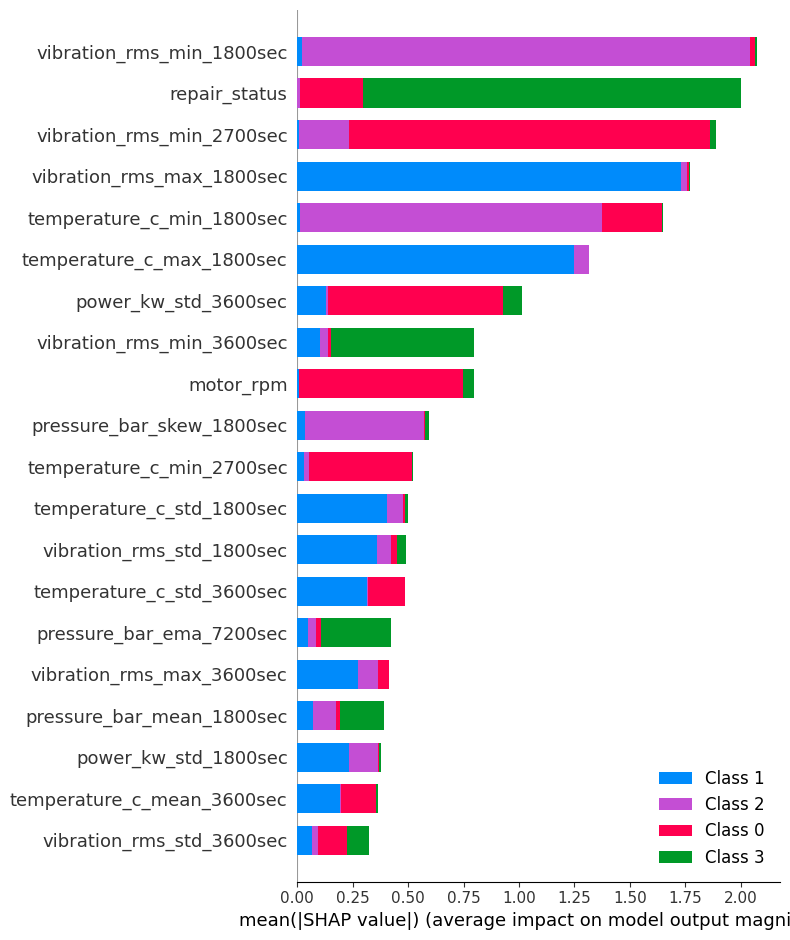

Window 300sec features: []
Window 600sec features: ['pressure_bar_mean_600sec', 'pressure_bar_std_600sec', 'pressure_bar_min_600sec', 'pressure_bar_max_600sec', 'pressure_bar_skew_600sec', 'pressure_bar_kurt_600sec', 'temperature_c_mean_600sec', 'temperature_c_std_600sec', 'temperature_c_min_600sec', 'temperature_c_max_600sec', 'temperature_c_skew_600sec', 'temperature_c_kurt_600sec', 'vibration_rms_mean_600sec', 'vibration_rms_std_600sec', 'vibration_rms_min_600sec', 'vibration_rms_max_600sec', 'vibration_rms_skew_600sec', 'vibration_rms_kurt_600sec', 'power_kw_mean_600sec', 'power_kw_std_600sec', 'power_kw_min_600sec', 'power_kw_max_600sec', 'power_kw_skew_600sec', 'power_kw_kurt_600sec', 'pressure_bar_change_rate_600sec', 'temperature_c_change_rate_600sec', 'vibration_rms_change_rate_600sec', 'power_kw_change_rate_600sec', 'pressure_bar_mean_3600sec', 'pressure_bar_std_3600sec', 'pressure_bar_min_3600sec', 'pressure_bar_max_3600sec', 'pressure_bar_skew_3600sec', 'pressure_bar_kurt_3

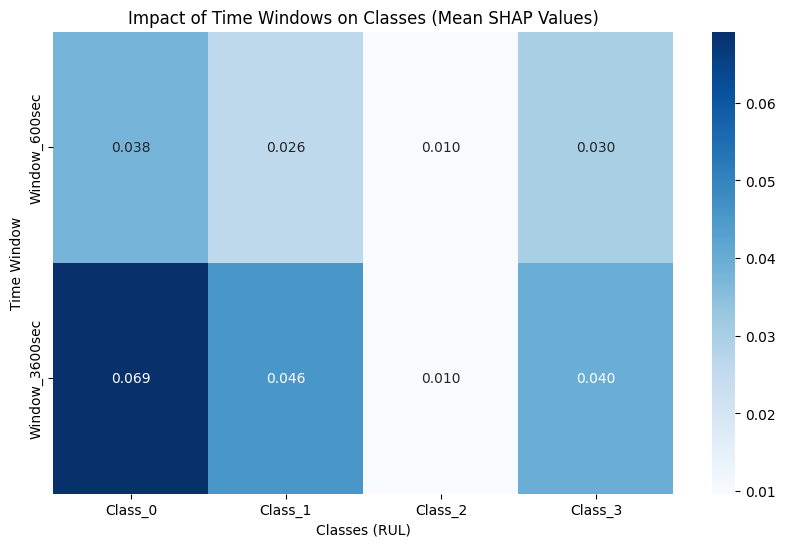

In [ ]:
import numpy as np
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import joblib
from sklearn.inspection import permutation_importance

# Define the maximum TTF for classification
max_classification_ttf = 7200.0

# Load the model
model_path = f'xgboost_multiclass_rul_prediction_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.json'
best_model = xgb.XGBClassifier()
best_model.load_model(model_path)
print("Model loaded successfully.")

# Load the scaler
scaler_path = f'scaler_multiclass_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.pkl'
scaler = joblib.load(scaler_path)
print("Scaler loaded successfully.")

# Load the feature list
with open(f'features_list_ttf_{int(max_classification_ttf)}sec.pkl', 'rb') as f:
    features = pickle.load(f)
print("Features list loaded successfully.")

# Load test data
with open(f'test_data_ttf_{int(max_classification_ttf)}sec.pkl', 'rb') as f:
    X_test_scaled, y_test = pickle.load(f)
print("Test data (X_test_scaled, y_test) loaded successfully.")

# Convert X_test_scaled to DataFrame for easier feature handling
X_test = pd.DataFrame(X_test_scaled, columns=features)

# 1. SHAP Analysis
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_scaled)

# Calculate mean absolute SHAP values to determine feature importance
shap_values_abs = np.abs(shap_values).mean(axis=0)  # Mean SHAP values across all classes
shap_importance = pd.DataFrame({
    'Feature': features,
    'Mean_Abs_SHAP': shap_values_abs.mean(axis=1)  # Mean across classes (corrected axis)
})
shap_importance = shap_importance.sort_values(by='Mean_Abs_SHAP', ascending=False)

# Select top 20 features
top_features = shap_importance['Feature'].head(20).values
top_feature_indices = [features.index(f) for f in top_features]

# Plot SHAP summary for top 20 features
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values[:, top_feature_indices, :],
                  X_test_scaled[:, top_feature_indices],
                  feature_names=top_features,
                  plot_type="bar",
                  title="Feature Importance (SHAP) for Top 20 Features")
plt.show()



# 2. Window Analysis
window_sizes_points = [300, 600, 1200, 2400, 3000, 3600, 4800]
grouped_shap_values = {}

for window_size in window_sizes_points:
    # Select features related to the window
    window_features = [f for f in features if f'{window_size}sec' in f]
    print(f"Window {window_size}sec features: {window_features}")  # Debug print
    window_feature_indices = [features.index(f) for f in window_features]

    # Calculate mean SHAP values for this window
    if window_feature_indices:
        window_shap = np.abs(shap_values[:, window_feature_indices, :]).mean(axis=1)  # Mean across features
        grouped_shap_values[f'Window_{window_size}sec'] = window_shap.mean(axis=0)  # Mean across samples

# Convert to DataFrame for plotting
grouped_shap_df = pd.DataFrame(list(grouped_shap_values.values()), index=grouped_shap_values.keys(), columns=[f'Class_{i}' for i in range(shap_values.shape[2])])
print("Mean SHAP Impact for Each Time Window Across Classes:")
print(grouped_shap_df)

# Plot the impact
plt.figure(figsize=(10, 6))
sns.heatmap(grouped_shap_df, annot=True, cmap='Blues', fmt='.3f')
plt.title("Impact of Time Windows on Classes (Mean SHAP Values)")
plt.xlabel("Classes (RUL)")
plt.ylabel("Time Window")
plt.show()


--- مرحلة تحميل ومعالجة البيانات الأولية ---
لا توجد قيم NaN في البيانات.

DataFrame بعد الحذف الآمن للأعمدة:
          time_min    motor_rpm  pressure_bar  temperature_c  vibration_rms  \
75721  1262.016667  1500.646431      7.941966      68.933547       1.970875   
80184  1336.400000     0.000000      5.880454      35.504751       0.152569   
19864   331.066667    20.606411      5.569735      41.536825       0.082182   
76699  1278.316667  1517.267700      5.816136      40.196955       1.032748   
92991  1549.850000    80.397557      8.000000      74.418506       0.305479   

       power_kw  airflow_demand_cfm  torque_nm   noise_db  oilpump_power_w  \
75721  5.000000            1.845698  25.403261  59.259625        45.502368   
80184  0.000000            1.638700   0.000000  40.000000         0.464601   
19864  0.000000            1.140073   0.000000  41.635522         8.833645   
76699  4.988366            2.000000  35.338295  59.294894        22.395392   
92991  0.385515          

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [13:36:12] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


Best Parameters: {'subsample': 0.4, 'reg_lambda': 0.5, 'reg_alpha': 0.5, 'n_estimators': 800, 'max_depth': 15, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
--- مرحلة التنبؤ وتقييم الأداء ---
Validation Set Performance:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6782
           1       0.95      0.99      0.97        76
           2       1.00      0.79      0.88        84
           3       0.99      0.98      0.99       125
           4       0.96      0.98      0.97       128
           5       0.95      0.97      0.96       191

    accuracy                           0.99      7386
   macro avg       0.98      0.95      0.96      7386
weighted avg       0.99      0.99      0.99      7386

Test Set Performance:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      6782
           1       0.96      1.00      0.98        77
           2       1.00      0.87      0.93       

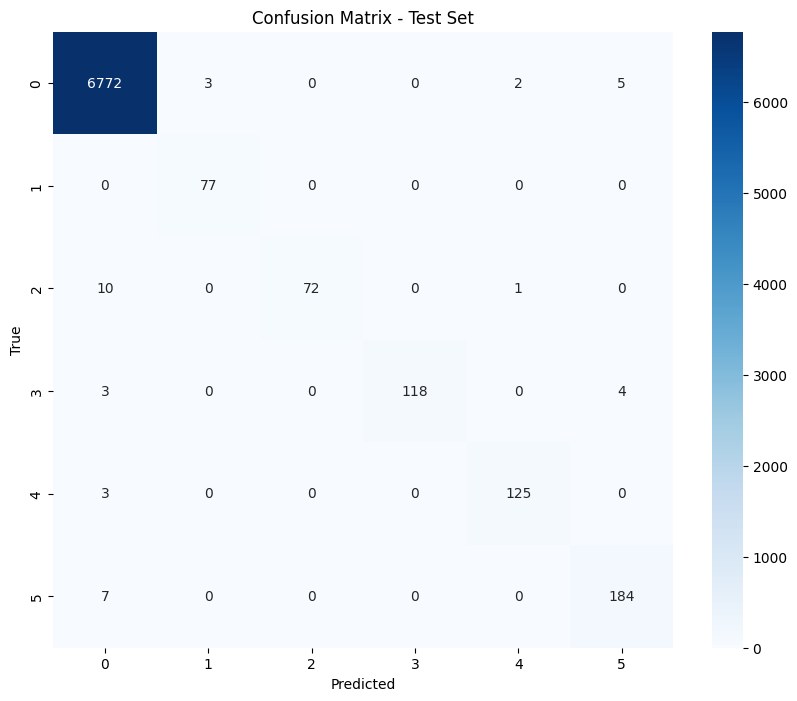

--- أهمية الميزات (XGBoost) ---
Feature Importance:
                    Feature  Importance
3             temperature_c    0.195063
0                 motor_rpm    0.125708
2              pressure_bar    0.113029
12         power_moving_avg    0.101710
6      vibration_moving_avg    0.097932
4                  power_kw    0.097884
10                 noise_db    0.071235
1             vibration_rms    0.056381
14            anomaly_score    0.047188
9        airflow_demand_cfm    0.024921
7   temperature_change_rate    0.016406
13            vibration_std    0.016025
5      pressure_change_rate    0.013988
8                 torque_nm    0.012381
11          oilpump_power_w    0.010150


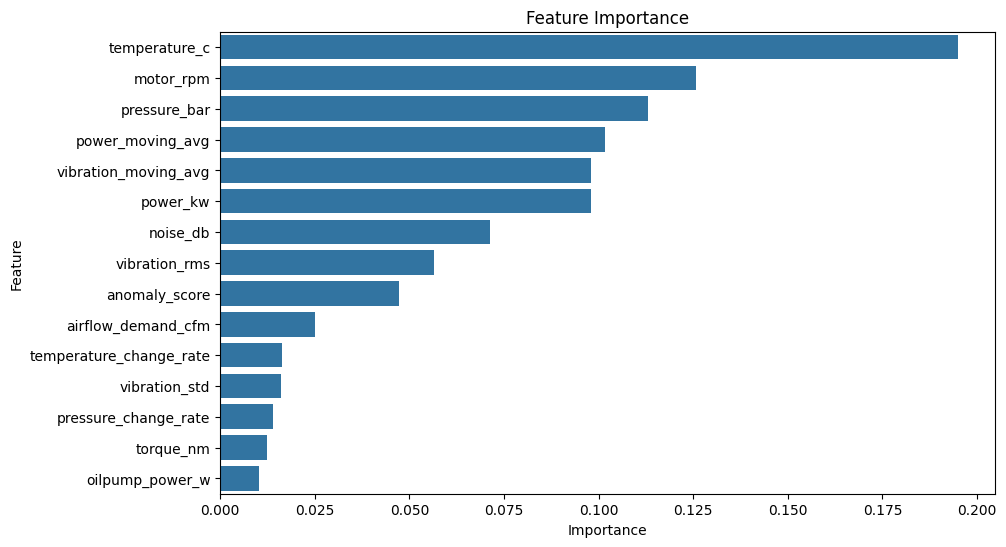

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import time
import joblib
import shap
from sklearn.ensemble import IsolationForest
from scipy.stats import uniform, randint

# قياس وقت التنفيذ
start_time = time.time()

# --- 1. تحميل البيانات والمعالجة الأولية ---
print("--- مرحلة تحميل ومعالجة البيانات الأولية ---")
df = pd.read_csv("/content/noisy_compressor_data_v5 (1).csv").sample(frac=0.5, random_state=42)
#/content/enhanced_compressor_data_v4_modified_power_noise (1).csv
# التأكد من عدم وجود قيم NaN
df = df.dropna()
if df.isna().sum().sum() > 0:
    print("تحذير: لا تزال هناك قيم NaN في البيانات!")
else:
    print("لا توجد قيم NaN في البيانات.")
# df = pd.read_csv('your_file.csv')

# قائمة بأسماء الأعمدة التي قد تكون موجودة أو غير موجودة
columns_to_drop_safely = ['temperature_change_rate', 'pressure_change_rate', 'vibration_moving_avg']

df.drop(columns_to_drop_safely, axis=1, inplace=True, errors='ignore')

print("\nDataFrame بعد الحذف الآمن للأعمدة:")
print(df.head())
# ترتيب البيانات حسب الوقت (مهم للميزات المستندة إلى الوقت)
df = df.sort_values(by='id').reset_index(drop=True)

# --- 2. هندسة الميزات ---
print("--- مرحلة هندسة الميزات ---")

# temperature_change_rate
df['temperature_change_rate'] = 0.0
window_size =6
if len(df) > window_size:
    df['temp_diff'] = df['temperature_c'].diff(periods=window_size)
    df['time_diff'] = (df['time_min'] * 60).diff(periods=window_size)
    df['temperature_change_rate'] = df['temp_diff'] / df['time_diff'].replace(0, np.nan)
    df['temperature_change_rate'] = df['temperature_change_rate'].fillna(0.0)
df = df.drop(columns=['temp_diff', 'time_diff'], errors='ignore')
if len(df) > window_size:
    df['pressure_diff'] = df['pressure_bar'].diff(periods=window_size)
    df['time_diff'] = (df['time_min'] * 60).diff(periods=window_size)
    df['pressure_change_rate'] = df['pressure_diff'] / df['time_diff'].replace(0, np.nan)
    df['pressure_change_rate'] = df['pressure_change_rate'].fillna(0.0)
df = df.drop(columns=['pressure_diff', 'time_diff'], errors='ignore')
# power_moving_avg
df['power_moving_avg'] = df['power_kw'].rolling(window=5, min_periods=1).mean()
df['vibration_moving_avg'] = df['vibration_rms'].rolling(window=5, min_periods=1).mean()

# vibration_std
df['vibration_std'] = df['vibration_rms'].rolling(window=5, min_periods=1).std()
df['vibration_std'] = df['vibration_std'].fillna(0.0)

# تحويل time_since_last_repair إلى دقائق
df['time_since_last_repair'] = df['time_since_last_repair'] / 60

# تصفية أنواع الأعطال
df = df[df['fault_type'].isin([0, 1, 2, 3, 4, 5])]

# --- 3. اختيار الميزات وتطبيق Isolation Forest ---
print("--- مرحلة اختيار الميزات وتطبيق Isolation Forest ---")
X = df[['motor_rpm', 'vibration_rms', 'pressure_bar', 'temperature_c', 'power_kw',
        'pressure_change_rate', 'vibration_moving_avg', 'temperature_change_rate',
        'torque_nm', 'airflow_demand_cfm', 'noise_db', 'oilpump_power_w', 'power_moving_avg','vibration_std']]
y = df['fault_type']

iso_forest = IsolationForest(contamination=0.1, random_state=42)
iso_scores = iso_forest.fit_predict(X)
anomaly_scores = -iso_forest.decision_function(X)

X_with_anomaly = X.copy()
X_with_anomaly['anomaly_score'] = anomaly_scores
X = X_with_anomaly

detected_anomalies = iso_scores == -1
true_anomalies = y != 0

# --- 4. تقسيم البيانات وتوحيد المقاييس ---
print("--- مرحلة تقسيم البيانات وتوحيد المقاييس ---")
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# --- 5. معالجة عدم التوازن باستخدام SMOTE ---
print("--- مرحلة معالجة عدم التوازن (SMOTE) ---")
min_samples_per_class = 1000
smote = SMOTE(random_state=42, sampling_strategy={cls: max(min_samples_per_class, sum(y_train == cls)) for cls in np.unique(y_train)})
X_train_scaled_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

# تحويل الفئات إلى أرقام متتالية
label_mapping = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5}
y_train_mapped = y_train_smote.map(label_mapping)
y_val_mapped = y_val.map(label_mapping)
y_test_mapped = y_test.map(label_mapping)

# في هذه الحالة، قم بإنشاء النموذج مباشرةً:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'max_depth': [10,15,25],
    'learning_rate': [0.01, 0.03, 0.05],
    'n_estimators': [800],
    'subsample': [0.6, 0.8,0.5,0.4],
    'colsample_bytree': [0.3, 0.4, 0.5,0.2,0.6],
    'reg_lambda': [0.1, 0.5,0.3],
    'reg_alpha': [0.1, 0.5,0.3]
}

xgb_model = XGBClassifier(
    random_state=42,
    use_label_encoder=False,
    eval_metric='mlogloss'  # استخدام mlogloss أثناء التدريب
)

random_search = RandomizedSearchCV(
    xgb_model,
    param_distributions=param_dist,
    n_iter=10,
    scoring='f1_macro',  # تحسين بناءً على f1_macro
    cv=3,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_scaled_smote, y_train_mapped)
best_model = random_search.best_estimator_
print("Best Parameters:", random_search.best_params_)
# ثم انتقل مباشرة إلى التنبؤ والتقييم باستخدام best_model
# --- 7. التنبؤ وتقييم الأداء (باستخدام best_model) ---
print("--- مرحلة التنبؤ وتقييم الأداء ---")

# الآن استخدم best_model الذي تم تدريبه وتحسينه
y_val_pred_mapped = best_model.predict(X_val_scaled)
y_test_pred_mapped = best_model.predict(X_test_scaled)

# بقية الكود تبقى كما هي...

# إعادة تحويل التنبؤات إلى الفئات الأصلية
reverse_mapping = {v: k for k, v in label_mapping.items()}
y_val_pred = pd.Series(y_val_pred_mapped).map(reverse_mapping)
y_test_pred = pd.Series(y_test_pred_mapped).map(reverse_mapping)

print("Validation Set Performance:")
print(classification_report(y_val, y_val_pred))
print("Test Set Performance:")
print(classification_report(y_test, y_test_pred))

f1_macro = f1_score(y_test, y_test_pred, average='macro')
f1_weighted = f1_score(y_test, y_test_pred, average='weighted')
print(f"F1-score (macro): {f1_macro:.3f}")
print(f"F1-score (weighted): {f1_weighted:.3f}")

# --- 8. رسم مصفوفة الارتباك ---
print("--- رسم مصفوفة الارتباك ---")
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title('Confusion Matrix - Test Set')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# --- 9. أهمية الميزات ---
print("--- أهمية الميزات (XGBoost) ---")
importances = best_model.feature_importances_ # <-- قم بالتعديل هنا إلى best_model
feature_names = X.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print("Feature Importance:")
print(feature_importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
plt.title('Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()


### Parameter search results

Best Parameters: `{'subsample': 0.6, 'reg_lambda': 0.1, 'reg_alpha': 0.5, 'n_estimators': 800, 'max_depth': 25, 'learning_rate': 0.05, 'colsample_bytree': 0.5}`

Best Parameters: `{'subsample': 0.6, 'reg_lambda': 0.1, 'reg_alpha': 0.5, 'n_estimators': 1000, 'max_depth': 25, 'learning_rate': 0.05, 'colsample_bytree': 0.5}`

Applying feature engineering to training data...


<ipython-input-8-af57d1b5aab1>:57: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_df = data_df.fillna(method='bfill').fillna(0)


Applying feature engineering to test data...


<ipython-input-8-af57d1b5aab1>:57: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_df = data_df.fillna(method='bfill').fillna(0)



Data points in training set (0 < TTF <= 7200 seconds): 80000
Data points in test set (0 < TTF <= 7200 seconds): 19368

Calculated Class Weights: {np.int64(0): np.float64(2.346316283435007), np.int64(1): np.float64(0.5319148936170213), np.int64(2): np.float64(0.6949511796796275), np.int64(3): np.float64(3.9238767902687854)}

Distribution of RUL Classes in Training Set:
rul_class
0     8524
1    37600
2    28779
3     5097
Name: count, dtype: int64

Training XGBoost model with manually selected parameters...

Training finished using the best model.

--- Multi-class Classification Performance (Original Test Set, RUL 0-7200 seconds) ---
Overall Accuracy: 0.934

Classification Report:
              precision    recall  f1-score   support

    0-10 min       0.98      0.86      0.92      2493
   10-30 min       0.90      1.00      0.95      9400
   30-60 min       0.98      0.88      0.93      6584
  60-120 min       0.90      0.84      0.87       891

    accuracy                          

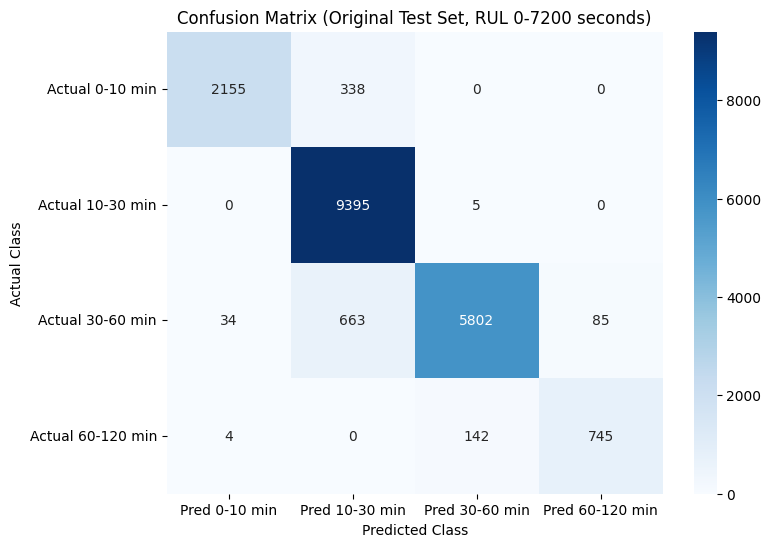


--- Sample of Multi-class Predictions (Original Test Set, RUL 0-7200 seconds) ---
     time_dhms  actual_rul_class  predicted_rul_class  actual_ttf_seconds  \
0   0:22:13:21                 2                    2              2704.0   
1   0:22:13:22                 2                    2              2703.0   
2   0:22:13:23                 2                    2              2702.0   
3   0:22:13:24                 2                    2              2701.0   
4   0:22:13:25                 2                    2              2700.0   
5   0:22:13:26                 2                    2              2699.0   
6   0:22:13:27                 2                    2              2698.0   
7   0:22:13:28                 2                    2              2697.0   
8   0:22:13:29                 2                    2              2696.0   
9   0:22:13:30                 2                    2              2695.0   
10  0:22:13:31                 2                    2              269

In [ ]:
# @title بدون SMOTE
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import class_weight
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pickle
import warnings
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# Function to convert seconds to days:hours:minutes:seconds format
def seconds_to_dhms(seconds):
    if pd.isna(seconds) or seconds < 0:
        return "N/A"
    days = int(seconds // (24 * 3600))
    seconds %= 24 * 3600
    hours = int(seconds // 3600)
    seconds %= 3600
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{days}:{hours:02d}:{minutes:02d}:{seconds:02d}"

# Function to create derived features with rolling windows in seconds
def create_features(data_df):
    data_df = data_df.sort_values(by='id').reset_index(drop=True)
    data_df = data_df.copy()
    epsilon = 1e-8  # Avoid division by zero

    window_sizes_points = [300, 600, 1200, 2400, 4800]
    core_features = ['pressure_bar', 'temperature_c', 'vibration_rms', 'power_kw']

    for window_size in window_sizes_points:
        if window_size > len(data_df):
            print(f"Warning: Window size {window_size} is larger than dataset length ({len(data_df)}). Skipping.")
            continue
        for col in core_features:
            data_df[f'{col}_mean_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).mean()
            data_df[f'{col}_std_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).std()
            data_df[f'{col}_min_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).min()
            data_df[f'{col}_max_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).max()
            if window_size > 2:
                data_df[f'{col}_skew_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).skew()
                data_df[f'{col}_kurt_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).kurt()
        for col in core_features:
            data_df[f'{col}_diff_{window_size}sec'] = data_df[col].diff(periods=window_size)
            data_df[f'time_diff_{window_size}sec'] = data_df['id'].diff(periods=window_size)
            data_df[f'{col}_change_rate_{window_size}sec'] = data_df[f'{col}_diff_{window_size}sec'] / (data_df[f'time_diff_{window_size}sec'] + epsilon)
            data_df = data_df.drop(columns=[f'{col}_diff_{window_size}sec', f'time_diff_{window_size}sec'], errors='ignore')

    for col in core_features:
        data_df[f'{col}_ema_7200sec'] = data_df[col].ewm(span=7200, adjust=False).mean()

    data_df = data_df.fillna(method='bfill').fillna(0)
    return data_df

# Function to map time_to_failure to RUL classes
def map_ttf_to_class(ttf):
    if pd.isna(ttf) or ttf <= 0 or ttf > 7200:
        return -1
    elif ttf <= 120:
        return 0
    elif ttf <= 2000:
        return 1
    elif ttf <= 3470:
        return 2
    elif ttf <= 7200:
        return 3
    else:
        return -1

# Load the dataset
try:
    df = pd.read_csv("enhanced_compressor_data_v4_with_ttf.csv")
except FileNotFoundError:
    print("Error: File 'enhanced_compressor_data_v4_with_ttf.csv' not found.")
    exit()

if 'id' not in df.columns or 'time_to_failure' not in df.columns:
    raise ValueError("Required columns ('id', 'time_to_failure') not found.")
df.dropna(subset=['time_to_failure'], inplace=True)

df = df.sort_values(by='id').reset_index(drop=True)

# Step 1: Split data temporally (80/20)
train_size_ratio = 0.8
train_size_index = int(train_size_ratio * len(df))
train_df = df.iloc[:train_size_index].copy()
test_df = df.iloc[train_size_index:].copy()

# Step 2: Apply feature engineering
print("Applying feature engineering to training data...")
train_df = create_features(train_df)
print("Applying feature engineering to test data...")
test_df = create_features(test_df)

# Step 3: Assign RUL classes
max_classification_ttf = 7200.0
train_df['rul_class'] = train_df['time_to_failure'].apply(map_ttf_to_class)
test_df['rul_class'] = test_df['time_to_failure'].apply(map_ttf_to_class)

train_df_filtered = train_df[(train_df['rul_class'] != -1) & (train_df['time_to_failure'] > 0)].copy()
test_df_filtered = test_df[(test_df['rul_class'] != -1) & (test_df['time_to_failure'] > 0)].copy()

print(f"\nData points in training set (0 < TTF <= {int(max_classification_ttf)} seconds): {len(train_df_filtered)}")
print(f"Data points in test set (0 < TTF <= {int(max_classification_ttf)} seconds): {len(test_df_filtered)}")

if len(train_df_filtered) == 0 or len(test_df_filtered) == 0:
    raise ValueError("Not enough data points in the specified TTF range for classification.")

# Step 4: Define features and target
exclude_cols = ['id', 'fault_type', 'time_to_failure', 'is_failure', 'rul_class', 'is_failure_soon', 'motor_health',
                'compressor_health', 'tank_health', 'blockage_factor', 'leak_rate_lpm', 'load_unload_cycles', 'time_since_last_repair']
features = [col for col in train_df_filtered.columns if col not in exclude_cols]
features = [f for f in features if not any(sub in f for sub in ['_short', '_long', '_diff'])]

X_train = train_df_filtered[features]
y_train = train_df_filtered['rul_class']
X_test = test_df_filtered[features]
y_test = test_df_filtered['rul_class']

# Step 5: Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 6: Compute class weights for original training data
classes = np.unique(y_train)
if len(classes) != 4:
    print(f"Warning: Found {len(classes)} unique classes in training data, expected 4.")
    print(f"Classes found: {classes}")
weights = class_weight.compute_class_weight('balanced', classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))
print("\nCalculated Class Weights:", class_weights)
print("\nDistribution of RUL Classes in Training Set:")
print(pd.Series(y_train).value_counts().sort_index())

# Step 7: Train XGBoost model with fixed parameters
fixed_params = {
    'n_estimators': 100,
    'max_depth': 15,
    'learning_rate': 0.1,
    'subsample': 0.7,
    'colsample_bytree': 0.7,
    'min_child_weight': 1,
    'gamma': 0.1,
    'reg_alpha': 0.01,
    'reg_lambda': 0.001
}

best_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=len(classes),
    random_state=42,
    eval_metric='mlogloss',
    **fixed_params
)

print("\nTraining XGBoost model with manually selected parameters...")
best_model.fit(X_train_scaled, y_train,
               sample_weight=np.array([class_weights[i] for i in y_train]))
print("\nTraining finished using the best model.")

# Step 8: Evaluate on original test set
y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)

unique_classes = np.unique(y_test)
class_names = [
    '0-10 min' if 0 in unique_classes else None,
    '10-30 min' if 1 in unique_classes else None,
    '30-60 min' if 2 in unique_classes else None,
    '60-120 min' if 3 in unique_classes else None
]
class_names = [name for name in class_names if name is not None]

print(f"\n--- Multi-class Classification Performance (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds) ---")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names, labels=unique_classes))

cm = confusion_matrix(y_test, y_pred, labels=unique_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'Pred {name}' for name in class_names],
            yticklabels=[f'Actual {name}' for name in class_names])
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title(f'Confusion Matrix (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds)')
plt.show()

# Step 9: Analyze predictions on original test set
test_df_results = test_df_filtered.copy().reset_index(drop=True)
test_df_results['predicted_rul_class'] = y_pred
test_df_results['actual_rul_class'] = y_test.values
test_df_results['predicted_proba'] = [y_pred_proba[i, predicted_class] for i, predicted_class in enumerate(y_pred)]
test_df_results['actual_ttf_seconds'] = test_df_filtered['time_to_failure'].values
test_df_results['time_dhms'] = test_df_results['id'].apply(seconds_to_dhms)

print(f"\n--- Sample of Multi-class Predictions (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds) ---")
print(test_df_results[['time_dhms', 'actual_rul_class', 'predicted_rul_class', 'actual_ttf_seconds', 'predicted_proba']].head(20))

# Analyze warnings (RUL <= 3600 seconds)
warning_classes = [0, 1, 2]
warning_classes_names = ['0-600 sec', '600-1800 sec', '1800-3600 sec']
warning_schedule_analysis = test_df_results[test_df_results['predicted_rul_class'].isin(warning_classes)].copy()

if not warning_schedule_analysis.empty:
    print(f"\n--- Analysis for Warnings Triggered (Predicted RUL {warning_classes_names}: 0-3600 seconds) ---")
    print("Actual RUL (seconds) distribution when a warning is triggered:")
    print(warning_schedule_analysis['actual_ttf_seconds'].describe())
    true_positives_warnings = warning_schedule_analysis[warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    false_positives_warnings = warning_schedule_analysis[~warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    print(f"\nBreakdown of Warnings:")
    print(f"Total Warnings Triggered: {len(warning_schedule_analysis)}")
    if len(warning_schedule_analysis) > 0:
        print(f"  True Warnings (Actual RUL <= 3600 secs): {len(true_positives_warnings)} ({len(true_positives_warnings)/len(warning_schedule_analysis):.1%})")
        print(f"  False Warnings (Actual RUL > 3600 secs): {len(false_positives_warnings)} ({len(false_positives_warnings)/len(warning_schedule_analysis):.1%})")
        if not false_positives_warnings.empty:
            print("  Actual RUL (seconds) for False Warnings:")
            print(false_positives_warnings['actual_ttf_seconds'].describe())
    actual_failures_in_warning_range = test_df_results[test_df_results['actual_rul_class'].isin(warning_classes)]
    missed_warnings = actual_failures_in_warning_range[~actual_failures_in_warning_range['predicted_rul_class'].isin(warning_classes)]
    print(f"\nAnalysis of Missed Warnings (Actual RUL <= 3600 secs):")
    print(f"Total Actual Failure points in 0-3600 sec range: {len(actual_failures_in_warning_range)}")
    if len(actual_failures_in_warning_range) > 0:
        print(f"  Missed Warnings: {len(missed_warnings)} ({len(missed_warnings)/len(actual_failures_in_warning_range):.1%})")
        if not missed_warnings.empty:
            print("  Actual RUL (seconds) for Missed Warnings:")
            print(missed_warnings['actual_ttf_seconds'].describe())
else:
    print(f"\nNo warnings triggered based on Predicted RUL {warning_classes_names}.")

# Step 10: Save model, scaler, features, and test data
best_model.save_model(f'xgboost_multiclass_rul_prediction_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.json')
print(f"\nXGBoost Multi-class RUL Prediction model saved.")
joblib.dump(scaler, f'scaler_multiclass_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.pkl')
print("Scaler saved successfully.")

with open(f'features_list_ttf_{int(max_classification_ttf)}sec.pkl', 'wb') as f:
    pickle.dump(features, f)
print("Features list saved successfully.")

with open(f'test_data_ttf_{int(max_classification_ttf)}sec.pkl', 'wb') as f:
    pickle.dump((X_test_scaled, y_test), f)
print("Test data (X_test_scaled, y_test) saved successfully.")

Applying feature engineering to training data...


<ipython-input-87-45d435cdad63>:58: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_df = data_df.fillna(method='bfill').fillna(0)


Applying feature engineering to test data...


<ipython-input-87-45d435cdad63>:58: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data_df = data_df.fillna(method='bfill').fillna(0)



Data points in training set (0 < TTF <= 7200 seconds): 80000
Data points in test set (0 < TTF <= 7200 seconds): 19368

Calculated Class Weights: {np.int64(0): np.float64(1.0), np.int64(1): np.float64(1.0), np.int64(2): np.float64(1.0)}

Distribution of RUL Classes in Resampled Training Set:
rul_class
0    36124
1    36124
2    36124
Name: count, dtype: int64

Training XGBoost model with manually selected parameters...

Training finished using the manually configured model.

--- Multi-class Classification Performance (Original Test Set, RUL 0-7200 seconds) ---
Overall Accuracy: 0.939

Classification Report:
                         precision    recall  f1-score   support

  0-1000 sec (Critical)       0.92      0.99      0.95      9393
1000-3500 sec (Warning)       0.97      0.89      0.93      8404
3500-7200 sec (Healthy)       0.91      0.93      0.92      1571

               accuracy                           0.94     19368
              macro avg       0.93      0.93      0.93    

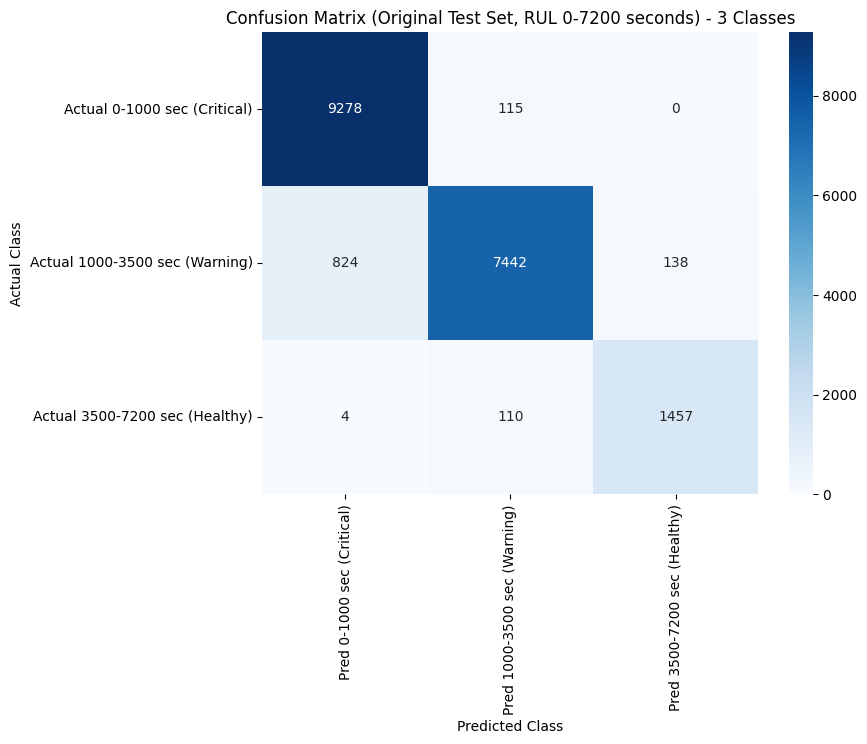


--- Sample of Multi-class Predictions (Original Test Set, RUL 0-7200 seconds) ---
     time_dhms  actual_rul_class  predicted_rul_class  actual_ttf_seconds  \
0   0:22:13:21                 1                    1              2704.0   
1   0:22:13:22                 1                    1              2703.0   
2   0:22:13:23                 1                    1              2702.0   
3   0:22:13:24                 1                    1              2701.0   
4   0:22:13:25                 1                    1              2700.0   
5   0:22:13:26                 1                    1              2699.0   
6   0:22:13:27                 1                    1              2698.0   
7   0:22:13:28                 1                    1              2697.0   
8   0:22:13:29                 1                    1              2696.0   
9   0:22:13:30                 1                    1              2695.0   
10  0:22:13:31                 1                    1              269

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils import class_weight
# from sklearn.model_selection import RandomizedSearchCV # لم نعد نستخدم RandomizedSearchCV
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from imblearn.over_sampling import SMOTE
import pickle  # لتخزين البيانات

# Function to convert seconds to days:hours:minutes:seconds format
def seconds_to_dhms(seconds):
    if pd.isna(seconds) or seconds < 0:
        return "N/A"
    days = int(seconds // (24 * 3600))
    seconds %= 24 * 3600
    hours = int(seconds // 3600)
    seconds %= 3600
    minutes = int(seconds // 60)
    seconds = int(seconds % 60)
    return f"{days}:{hours:02d}:{minutes:02d}:{seconds:02d}"

# Function to create derived features with rolling windows in seconds
def create_features(data_df):
    data_df = data_df.sort_values(by='id').reset_index(drop=True)
    data_df = data_df.copy()
    epsilon = 1e-8  # Avoid division by zero

    # تحديث window_sizes_points لتناسب الفئات الجديدة
    window_sizes_points = [600, 1000, 2000, 3500, 5000, 7000] # قيم جديدة
    core_features = ['pressure_bar', 'temperature_c', 'vibration_rms', 'power_kw']

    for window_size in window_sizes_points:
        if window_size > len(data_df):
            print(f"Warning: Window size {window_size} is larger than dataset length ({len(data_df)}). Skipping.")
            continue
        for col in core_features:
            data_df[f'{col}_mean_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).mean()
            data_df[f'{col}_std_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).std()
            data_df[f'{col}_min_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).min()
            data_df[f'{col}_max_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).max()
            if window_size > 2:
                data_df[f'{col}_skew_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).skew()
                data_df[f'{col}_kurt_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).kurt()
        for col in core_features:
            data_df[f'{col}_diff_{window_size}sec'] = data_df[col].diff(periods=window_size)
            data_df[f'time_diff_{window_size}sec'] = data_df['id'].diff(periods=window_size)
            data_df[f'{col}_change_rate_{window_size}sec'] = data_df[f'{col}_diff_{window_size}sec'] / (data_df[f'time_diff_{window_size}sec'] + epsilon)
            data_df = data_df.drop(columns=[f'{col}_diff_{window_size}sec', f'time_diff_{window_size}sec'], errors='ignore')

    # Add EMA feature for 7200 seconds (يمكنك تعديلها إذا كانت الفئات أطول)
    for col in core_features:
        data_df[f'{col}_ema_7200sec'] = data_df[col].ewm(span=7200, adjust=False).mean()

    data_df = data_df.fillna(method='bfill').fillna(0)
    return data_df

# Function to map time_to_failure to RUL classes (NEW: 3 classes)
def map_ttf_to_class(ttf):
    if pd.isna(ttf) or ttf <= 0 or ttf > 7200:
        return -1
    # الفئة 0: حرج / خطر قريب جداً (0 < TTF <= 1000 ثانية)
    elif ttf <= 1500:
        return 0
    # الفئة 1: تحذير / خطر متوسط (1000 < TTF <= 3500 ثانية)
    elif ttf <= 3300:
        return 1
    # الفئة 2: سليم / خطر بعيد (3500 < TTF <= 7200 ثانية)
    elif ttf <= 7200:
        return 2
    else:
        return -1

# Load the dataset
try:
    df = pd.read_csv("enhanced_compressor_data_v4_with_ttf.csv")
except FileNotFoundError:
    print("Error: File 'enhanced_compressor_data_v4_with_ttf.csv' not found.")
    exit()

# Verify 'id' and 'time_to_failure' columns
if 'id' not in df.columns or 'time_to_failure' not in df.columns:
    raise ValueError("Required columns ('id', 'time_to_failure') not found.")
df.dropna(subset=['time_to_failure'], inplace=True)

# Sort by 'id' and reset index
df = df.sort_values(by='id').reset_index(drop=True)

# Step 1: Split data temporally (80/20)
train_size_ratio = 0.8
train_size_index = int(train_size_ratio * len(df))
train_df = df.iloc[:train_size_index].copy()
test_df = df.iloc[train_size_index:].copy()

# Step 2: Apply feature engineering
print("Applying feature engineering to training data...")
train_df = create_features(train_df)
print("Applying feature engineering to test data...")
test_df = create_features(test_df)

# Step 3: Assign RUL classes
max_classification_ttf = 7200.0
train_df['rul_class'] = train_df['time_to_failure'].apply(map_ttf_to_class)
test_df['rul_class'] = test_df['time_to_failure'].apply(map_ttf_to_class)

# Filter data to keep valid RUL classes
train_df_filtered = train_df[(train_df['rul_class'] != -1) & (train_df['time_to_failure'] > 0)].copy()
test_df_filtered = test_df[(test_df['rul_class'] != -1) & (test_df['time_to_failure'] > 0)].copy()

print(f"\nData points in training set (0 < TTF <= {int(max_classification_ttf)} seconds): {len(train_df_filtered)}")
print(f"Data points in test set (0 < TTF <= {int(max_classification_ttf)} seconds): {len(test_df_filtered)}")

if len(train_df_filtered) == 0 or len(test_df_filtered) == 0:
    raise ValueError("Not enough data points in the specified TTF range for classification.")

# Step 4: Define features and target
exclude_cols = ['id', 'fault_type', 'time_to_failure', 'is_failure', 'rul_class', 'is_failure_soon', 'motor_health',
               'compressor_health', 'tank_health', 'blockage_factor', 'leak_rate_lpm', 'load_unload_cycles','time_since_last_repair']
features = [col for col in train_df_filtered.columns if col not in exclude_cols]
features = [f for f in features if not any(sub in f for sub in ['_short', '_long', '_diff'])]

X_train = train_df_filtered[features]
y_train = train_df_filtered['rul_class']
X_test = test_df_filtered[features]
y_test = test_df_filtered['rul_class']

# Step 5: Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 6: Oversample training set with SMOTE
# سنستخدم السلوك الافتراضي لـ SMOTE (موازنة الفئات مع الأغلبية)
smote = SMOTE(random_state=42)
X_train_scaled_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# Step 7: Compute class weights for resampled training data
classes = np.unique(y_train_resampled)
# هنا يجب أن تكون len(classes) هي 3 بعد التغيير
if len(classes) != 3:
    print(f"Warning: Found {len(classes)} unique classes in training data, expected 3.")
    print(f"Classes found: {classes}")
weights = class_weight.compute_class_weight('balanced', classes=classes, y=y_train_resampled)
class_weights = dict(zip(classes, weights))
print("\nCalculated Class Weights:", class_weights)
print("\nDistribution of RUL Classes in Resampled Training Set:")
print(pd.Series(y_train_resampled).value_counts().sort_index())

# Step 8: Train XGBoost model with the desired parameters directly

# تحديد المعاملات التي تم اختيارها يدوياً
fixed_params = {
    'n_estimators': 100,     # عدد الأشجار الجديد
    'max_depth': 25,          # يمكن الاحتفاظ به أو زيادته قليلاً إلى 6 أو 7
    'learning_rate': 0.05,   # تم تخفيضه لتعويض زيادة عدد الأشجار
    'subsample': 0.7,
    'colsample_bytree': 0.7,
    'min_child_weight': 1,
    'gamma': 0.1,
    'reg_alpha': 0.005,
    'reg_lambda': 1
}

# تهيئة نموذج XGBClassifier باستخدام هذه المعاملات مباشرةً
best_model = xgb.XGBClassifier(
    objective='multi:softmax',
    num_class=len(classes), # سيتم تحديث هذا تلقائياً ليكون 3
    random_state=42,
    eval_metric='mlogloss',
    **fixed_params # هنا نمرر القاموس كمعاملات للنموذج
)

print("\nTraining XGBoost model with manually selected parameters...")

# تدريب النموذج مباشرةً
best_model.fit(X_train_scaled_resampled, y_train_resampled,
               sample_weight=np.array([class_weights[i] for i in y_train_resampled]))

print("\nTraining finished using the manually configured model.")


# Step 9: Evaluate on original test set
y_pred = best_model.predict(X_test_scaled)
y_pred_proba = best_model.predict_proba(X_test_scaled)

# تحديث class_names لتعكس الفئات الجديدة (3 فئات)
unique_classes = np.unique(y_test)
class_names = [
    '0-1000 sec (Critical)' if 0 in unique_classes else None,
    '1000-3500 sec (Warning)' if 1 in unique_classes else None,
    '3500-7200 sec (Healthy)' if 2 in unique_classes else None
]
class_names = [name for name in class_names if name is not None]

print(f"\n--- Multi-class Classification Performance (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds) ---")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification Report:")
# تأكد من أن labels يتطابق مع الترتيب الصحيح للفئات
print(classification_report(y_test, y_pred, target_names=class_names, labels=np.sort(unique_classes)))

cm = confusion_matrix(y_test, y_pred, labels=np.sort(unique_classes))
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f'Pred {name}' for name in class_names],
            yticklabels=[f'Actual {name}' for name in class_names])
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title(f'Confusion Matrix (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds) - 3 Classes')
plt.show()

# Step 10: Oversample test set for balanced evaluation (اختياري: قد لا تحتاج إلى هذا للتقييم النهائي)
# يفضل تقييم النموذج على مجموعة الاختبار الأصلية غير المتوازنة.
# ولكن إذا كنت ترغب في رؤية كيف يعمل النموذج على مجموعة اختبار متوازنة، احتفظ به.
smote_test = SMOTE(random_state=42)
X_test_scaled_resampled, y_test_resampled = smote_test.fit_resample(X_test_scaled, y_test)

# Predict on resampled test set
y_pred_resampled = best_model.predict(X_test_scaled_resampled)
y_pred_proba_resampled = best_model.predict_proba(X_test_scaled_resampled)

# Step 11: Analyze predictions on original test set
test_df_results = test_df_filtered.copy().reset_index(drop=True)
test_df_results['predicted_rul_class'] = y_pred
test_df_results['actual_rul_class'] = y_test.values
# في هذه الفئة، predicted_proba ستكون مصفوفة من صف واحد
# test_df_results['predicted_proba'] = [y_pred_proba[i, predicted_class] for i, predicted_class in enumerate(y_pred)]
# بدلاً من ذلك، احتفظ بكل الاحتمالات إذا أردت رؤية الثقة في كل فئة
test_df_results['predicted_proba_class0'] = y_pred_proba[:, 0]
test_df_results['predicted_proba_class1'] = y_pred_proba[:, 1]
test_df_results['predicted_proba_class2'] = y_pred_proba[:, 2] # تأكد أن هذا العمود موجود إذا كانت هناك 3 فئات

test_df_results['actual_ttf_seconds'] = test_df_filtered['time_to_failure'].values
test_df_results['time_dhms'] = test_df_results['id'].apply(seconds_to_dhms)

print(f"\n--- Sample of Multi-class Predictions (Original Test Set, RUL 0-{int(max_classification_ttf)} seconds) ---")
print(test_df_results[['time_dhms', 'actual_rul_class', 'predicted_rul_class', 'actual_ttf_seconds',
                       'predicted_proba_class0', 'predicted_proba_class1', 'predicted_proba_class2']].head(20))


# Analyze warnings (RUL <= 3500 seconds - New Class 0 and 1)
warning_classes = [0, 1] # الفئات الجديدة التي تعتبر تحذيرًا (0-1000 sec و 1000-3500 sec)
warning_classes_names = ['0-1000 sec (Critical)', '1000-3500 sec (Warning)']
warning_schedule_analysis = test_df_results[test_df_results['predicted_rul_class'].isin(warning_classes)].copy()

if not warning_schedule_analysis.empty:
    print(f"\n--- Analysis for Warnings Triggered (Predicted RUL {warning_classes_names}) ---")
    print("Actual RUL (seconds) distribution when a warning is triggered:")
    print(warning_schedule_analysis['actual_ttf_seconds'].describe())

    # تحديد True Positives و False Positives بناءً على الفئات الجديدة
    true_positives_warnings = warning_schedule_analysis[warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]
    false_positives_warnings = warning_schedule_analysis[~warning_schedule_analysis['actual_rul_class'].isin(warning_classes)]

    print(f"\nBreakdown of Warnings:")
    print(f"Total Warnings Triggered: {len(warning_schedule_analysis)}")
    if len(warning_schedule_analysis) > 0:
        print(f"  True Warnings (Actual RUL in critical/warning ranges): {len(true_positives_warnings)} ({len(true_positives_warnings)/len(warning_schedule_analysis):.1%})")
        print(f"  False Warnings (Actual RUL in healthy range): {len(false_positives_warnings)} ({len(false_positives_warnings)/len(warning_schedule_analysis):.1%})")
        if not false_positives_warnings.empty:
            print("  Actual RUL (seconds) for False Warnings:")
            print(false_positives_warnings['actual_ttf_seconds'].describe())

    # تحليل الإنذارات التي لم يتم رصدها (Missed Warnings)
    actual_failures_in_warning_range = test_df_results[test_df_results['actual_rul_class'].isin(warning_classes)]
    missed_warnings = actual_failures_in_warning_range[~actual_failures_in_warning_range['predicted_rul_class'].isin(warning_classes)]

    print(f"\nAnalysis of Missed Warnings (Actual RUL in critical/warning ranges):")
    print(f"Total Actual points in critical/warning ranges: {len(actual_failures_in_warning_range)}")
    if len(actual_failures_in_warning_range) > 0:
        print(f"  Missed Warnings: {len(missed_warnings)} ({len(missed_warnings)/len(actual_failures_in_warning_range):.1%})")
        if not missed_warnings.empty:
            print("  Actual RUL (seconds) for Missed Warnings:")
            print(missed_warnings['actual_ttf_seconds'].describe())
else:
    print(f"\nNo warnings triggered based on Predicted RUL {warning_classes_names}.")


# Step 12: Save model, scaler, features, and test data
# يجب تحديث اسم الملف ليعكس عدد الفئات الجديد
best_model.save_model(f'xgboost_multiclass_rul_prediction_3_classes_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.json')
print(f"\nXGBoost Multi-class RUL Prediction model saved.")
joblib.dump(scaler, f'scaler_multiclass_3_classes_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.pkl')
print("Scaler saved successfully.")

# حفظ قائمة الميزات
with open(f'features_list_3_classes_ttf_{int(max_classification_ttf)}sec.pkl', 'wb') as f:
    pickle.dump(features, f)
print("Features list saved successfully.")

# حفظ بيانات الاختبار (X_test_scaled و y_test)
with open(f'test_data_3_classes_ttf_{int(max_classification_ttf)}sec.pkl', 'wb') as f:
    pickle.dump((X_test_scaled, y_test), f)
print("Test data (X_test_scaled, y_test) saved successfully.")

In [ ]:
import numpy as np
import pandas as pd
import xgboost as xgb
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import joblib
from sklearn.inspection import permutation_importance

# تحديد الحد الأقصى لـ TTF
max_classification_ttf = 7200.0

# تحميل النموذج
model_path = f'xgboost_multiclass_rul_prediction_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.json'
best_model = xgb.XGBClassifier()
best_model.load_model(model_path)
print("Model loaded successfully.")

# تحميل المقيّم (Scaler)
scaler_path = f'scaler_multiclass_ttf_{int(max_classification_ttf)}sec_enhanced_tuned.pkl'
scaler = joblib.load(scaler_path)
print("Scaler loaded successfully.")

# تحميل قائمة الميزات
with open(f'features_list_ttf_{int(max_classification_ttf)}sec.pkl', 'rb') as f:
    features = pickle.load(f)
print("Features list loaded successfully.")

# تحميل بيانات الاختبار
with open(f'test_data_ttf_{int(max_classification_ttf)}sec.pkl', 'rb') as f:
    X_test_scaled, y_test = pickle.load(f)
print("Test data (X_test_scaled, y_test) loaded successfully.")

# تحويل X_test_scaled إلى DataFrame لتسهيل التعامل مع الميزات
X_test = pd.DataFrame(X_test_scaled, columns=features)

# 1. تحليل SHAP
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_scaled)

# حساب متوسط قيم SHAP المطلقة لتحديد أهم الميزات
shap_values_abs = np.abs(shap_values).mean(axis=0)  # متوسط قيم SHAP لكل ميزة عبر جميع الفئات
shap_importance = pd.DataFrame({
    'Feature': features,
    'Mean_Abs_SHAP': shap_values_abs.mean(axis=1)  # متوسط عبر الفئات
})
shap_importance = shap_importance.sort_values(by='Mean_Abs_SHAP', ascending=False)

# اختيار أهم 20 ميزة
top_features = shap_importance['Feature'].head(20).values
top_feature_indices = [features.index(f) for f in top_features]

# رسم ملخص SHAP لأهم 20 ميزة
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values[:, top_feature_indices, :],
                  X_test_scaled[:, top_feature_indices],
                  feature_names=top_features,
                  plot_type="bar",
                  title="أهمية الميزات (SHAP) لأهم 20 ميزة")
plt.show()

# رسم ملخص SHAP لكل فئة على حدة (مثال للفئة 0: 0-600 ثانية)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values[:, :, 0], X_test, feature_names=features,
                  title="تأثير الميزات على الفئة 0 (0-600 ثانية)")
plt.show()

# 2. تحليل النوافذ الزمنية
window_sizes_points = [300, 600, 1200, 2400, 4800]
grouped_shap_values = {}

for window_size in window_sizes_points:
    # اختيار الميزات المتعلقة بالنافذة
    window_features = [f for f in features if f'{window_size}sec' in f]
    window_feature_indices = [features.index(f) for f in window_features]

    # حساب متوسط قيم SHAP لهذه النافذة
    if window_feature_indices:
        window_shap = np.abs(shap_values[:, window_feature_indices, :]).mean(axis=1)  # متوسط عبر الميزات
        grouped_shap_values[f'Window_{window_size}sec'] = window_shap.mean(axis=0)  # متوسط عبر العينات

# تحويل إلى DataFrame للرسم
grouped_shap_df = pd.DataFrame(grouped_shap_values).T
print("متوسط تأثير SHAP لكل نافذة زمنية على الفئات:")
print(grouped_shap_df)

# رسم التأثير
plt.figure(figsize=(10, 6))
sns.heatmap(grouped_shap_df, annot=True, cmap='Blues', fmt='.3f')
plt.title("تأثير النوافذ الزمنية على الفئات (متوسط قيم SHAP)")
plt.xlabel("الفئات (RUL)")
plt.ylabel("النافذة الزمنية")
plt.show()

# 3. Permutation Importance
perm_importance = permutation_importance(best_model, X_test_scaled, y_test,
                                         scoring='f1_weighted', n_repeats=10, random_state=42)

# عرض النتائج
perm_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': perm_importance.importances_mean
})
perm_importance_df = perm_importance_df.sort_values(by='Importance', ascending=False)

# رسم أهم 20 ميزة
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=perm_importance_df.head(20))
plt.title("أهم 20 ميزة باستخدام Permutation Importance")
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# تحميل البيانات
df = pd.read_csv("/content/cleaned_enhanced_compressor_data_v5 (1).csv").sample(frac=0.5, random_state=42)
df = df.sort_values(by='time_min')

# إنشاء ميزة time_to_failure
df['time_to_failure'] = np.nan

# العثور على أوقات بدء الأعطال (fault_type من 1 إلى 5)
fault_starts = df[df['fault_type'].isin([1, 2, 3, 4, 5])].groupby('time_min').first().reset_index()
fault_times = fault_starts['time_min'].values

# لكل نقطة زمنية، ابحث عن أقرب عطل مستقبلي
for i, row in df.iterrows():
    current_time = row['time_min']
    future_faults = fault_times[fault_times > current_time]
    if len(future_faults) > 0:
        next_fault_time = future_faults[0]
        df.loc[i, 'time_to_failure'] = (next_fault_time - current_time) * 60  # بالثواني
    else:
        df.loc[i, 'time_to_failure'] = 0  # إذا لم يكن هناك عطل مستقبلي

# حفظ البيانات مع الميزة الجديدة
df.to_csv("enhanced_compressor_data_v4_with_ttf.csv", index=False)
print("تم إنشاء ميزة time_to_failure وحفظ البيانات في enhanced_compressor_data_v4_with_ttf.csv")

تم إنشاء ميزة time_to_failure وحفظ البيانات في enhanced_compressor_data_v4_with_ttf.csv


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb
from imblearn.over_sampling import SMOTE

# Create derived features with rolling windows
def create_features(data_df):
    data_df = data_df.sort_values(by='id').reset_index(drop=True).copy()
    window_sizes = [300, 600, 1200, 2400, 3000, 3600, 4800]  # Full window sizes
    core_features = ['pressure_bar', 'temperature_c', 'vibration_rms', 'power_kw']
    for window_size in window_sizes:
        if window_size > len(data_df):
            continue
        for col in core_features:
            data_df[f'{col}_mean_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).mean()
            data_df[f'{col}_std_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).std()
            data_df[f'{col}_min_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).min()
            data_df[f'{col}_max_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=1).max()
            if window_size > 2:
                data_df[f'{col}_skew_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).skew()
                data_df[f'{col}_kurt_{window_size}sec'] = data_df[col].rolling(window=window_size, min_periods=3).kurt()
            data_df[f'{col}_change_rate_{window_size}sec'] = data_df[col].diff(periods=window_size) / (data_df['id'].diff(periods=window_size) + 1e-8)
    for col in core_features:
        data_df[f'{col}_ema_7200sec'] = data_df[col].ewm(span=7200, adjust=False).mean()
    return data_df.fillna(method='bfill').fillna(0)

# Map time_to_failure to RUL classes
def map_ttf_to_class(ttf):
    if pd.isna(ttf) or ttf <= 0 or ttf > 7200:
        return -1
    elif ttf <= 600:
        return 0
    elif ttf <= 1800:
        return 1
    elif ttf <= 3600:
        return 2
    else:
        return 3

# Load and preprocess data
df = pd.read_csv("compressor_data_with_rul_labels.csv").sort_values(by='id').reset_index(drop=True)
df.dropna(subset=['time_to_failure'], inplace=True)

# Split data temporally (80/20)
train_size = int(0.8 * len(df))
train_df = df.iloc[:train_size].copy()
test_df = df.iloc[train_size:].copy()

# Apply feature engineering and RUL classification
train_df = create_features(train_df)
test_df = create_features(test_df)
train_df['rul_class'] = train_df['time_to_failure'].apply(map_ttf_to_class)
test_df['rul_class'] = test_df['time_to_failure'].apply(map_ttf_to_class)

# Filter valid RUL classes
train_df_filtered = train_df[train_df['rul_class'] != -1].copy()
test_df_filtered = test_df[test_df['rul_class'] != -1].copy()

# Define features and target
exclude_cols = ['id', 'fault_type', 'time_to_failure', 'is_failure', 'rul_class', 'is_failure_soon', 'motor_health',
                'compressor_health', 'tank_health', 'blockage_factor', 'leak_rate_lpm', 'load_unload_cycles', 'time_since_last_repair']
features = [col for col in train_df_filtered.columns if col not in exclude_cols]
X_train = train_df_filtered[features]
y_train = train_df_filtered['rul_class']
X_test = test_df_filtered[features]
y_test = test_df_filtered['rul_class']

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Oversample training set
smote = SMOTE(random_state=42)
X_train_scaled_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# Train XGBoost model
model = xgb.XGBClassifier(objective='multi:softmax', num_class=4, random_state=42, eval_metric='mlogloss')
param_dist = {
    'n_estimators': [50, 100, 200, 1000], 'max_depth': [10, 15, 25],
    'learning_rate': [0.01, 0.05, 0.1], 'subsample': [0.6, 0.8],
    'colsample_bytree': [0.6, 0.8], 'min_child_weight': [1, 3],
    'gamma': [0.0, 0.1], 'reg_alpha': [0.01, 0.1], 'reg_lambda': [0.001, 0.01]
}
random_search = RandomizedSearchCV(model, param_dist, n_iter=50, scoring='f1_weighted', cv=3, random_state=42, n_jobs=-1)
random_search.fit(X_train_scaled_resampled, y_train_resampled)
best_model = random_search.best_estimator_

# Evaluate model
y_pred = best_model.predict(X_test_scaled)
print("Test Set Performance:", classification_report(y_test, y_pred))
print(f"F1-score (weighted): {f1_score(y_test, y_pred, average='weighted'):.3f}")

